# Data Analysis

The purpose of this notebook is to analyse our data and create plots.

**Index**

- libraries
- settings
- helpers
- import data
- 01 - MOVEMENT & MODES
- 02 - CAMERA MOVEMENT & MODES
- 03 - CLUSTERING MOVEMENT & CAMERA
    - plot settings
    - create dataframe
    - camera movement histogram
    - 3d plot
    - 2d scatter of 3d plot
    - scaling
    - k-means
    - choosing k
    - outliers
- 03b - CLUSTERING MOVEMENT & CAMERA (ALL MODES)
    - settings
    - preparations
    - elbow & silhouette plots
    - k-means
    - 3d plots
    - export
- 04 - MCPLAYHD CONCEPT
    - settings
    - preprocessing
    - choosing k
    - extract replays
    - outliers
    - 3d plot of the first 3 components
- 04b - MCPLAYHD CONCEPT (ALL MODES)
    - settings
    - preparations
    - elbow & silhouette plots
    - k-means
    - 3d plots of the first 3 components
    - export
- 05 - BLOCKS PER CLICK
    - settings
    - preparations
    - elbow & silhouette plots
    - k-means
    - plot


## libraries

In [41]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


## settings

In [66]:
DATA_DIR = Path("../data")
EXPORT_DIR = DATA_DIR / "notebooks_exports"

WIDE_TABLE_PATH = EXPORT_DIR / "wide_table.csv"
SPEED_TO_BLOCK_PER_CLICK_PATH = EXPORT_DIR / "speed_to_block_per_click.csv"
MCPLAYHD_CONCEPT_PATH = EXPORT_DIR / "mcplayhd_concept.csv"

RANDOM_SEED = 42

DEFAULT_MODE_COLOR = "grey"
MODE_COLORS = {
    "EXTRASHORT": "C0",
    "SHORT": "C1",
    "NORMAL": "C2",
    "LONG": "C3",
    "INCLINEDSHORT": "C4",
    "INCLINED": "C5",
    "ONESTACK": "C6",
}

EXPORT_EXAMPLE_PERCENTILES = [0, 20, 40, 60, 80]
EXPORT_OUTLIER_COUNT = 10

## helpers

In [87]:
def cluster_export_rows(method, results):
    """takes a method + clustering results and returns a processed dataframe with samples for exporting"""
    rows = []
    for mode, result in results.items():
        ids = result["ids"]
        labels = result["labels"]
        distances = result["nearest_distances"]
        is_outlier = result["is_outlier"]

        for cluster in np.unique(labels):
            # skip if hdbscan noise
            if cluster == -1:
                continue

            # find the members of the cluster (except outliers)
            is_member = (labels == cluster) & ~is_outlier
            members = np.where(is_member)[0]

            if len(members) == 0:
                continue

            member_distances = distances[members]
            members = members[np.argsort(member_distances)]

            # logic to get 1 sample for each percentile
            added = set()
            for percentile in EXPORT_EXAMPLE_PERCENTILES:
                position = members[int(percentile / 100 * len(members))]
                if position in added:
                    continue
                added.add(position)

                rows.append({
                    "method": method,
                    "mode": mode,
                    "cluster": cluster,
                    "cluster_size": (labels == cluster).sum(),
                    "role": "center" if percentile == 0 else "example",
                    "rank": percentile,
                    "distance": distances[position],
                    "idAnonymous": ids[position],
                    "notes": "",
                })

        outliers = np.where(is_outlier)[0]
        outliers = outliers[np.argsort(distances[outliers])[::-1]]
        outliers = outliers[:EXPORT_OUTLIER_COUNT]
        for rank, position in enumerate(outliers):
              rows.append({
                "method": method,
                "mode": mode,
                "cluster": labels[position],
                "cluster_size": (labels == labels[position]).sum(),
                "role": "outlier",
                "rank": rank,
                "distance": distances[position],
                "idAnonymous": ids[position],
                "notes": "",
                })


    return pd.DataFrame(rows)


## import data

In [3]:
df_wide = pd.read_csv(WIDE_TABLE_PATH)
df_speed_to_block_per_click = pd.read_csv(SPEED_TO_BLOCK_PER_CLICK_PATH)
df_mcplayhd_concept = pd.read_csv(MCPLAYHD_CONCEPT_PATH)

print(f"wide: {df_wide.shape}")
print(f"speed to bpc: {df_speed_to_block_per_click.shape}")
print(f"mcplayhd: {df_mcplayhd_concept.shape}")

wide: (69301, 361)
speed to bpc: (69084, 5)
mcplayhd: (69005, 547)


## 01 - movement & modes

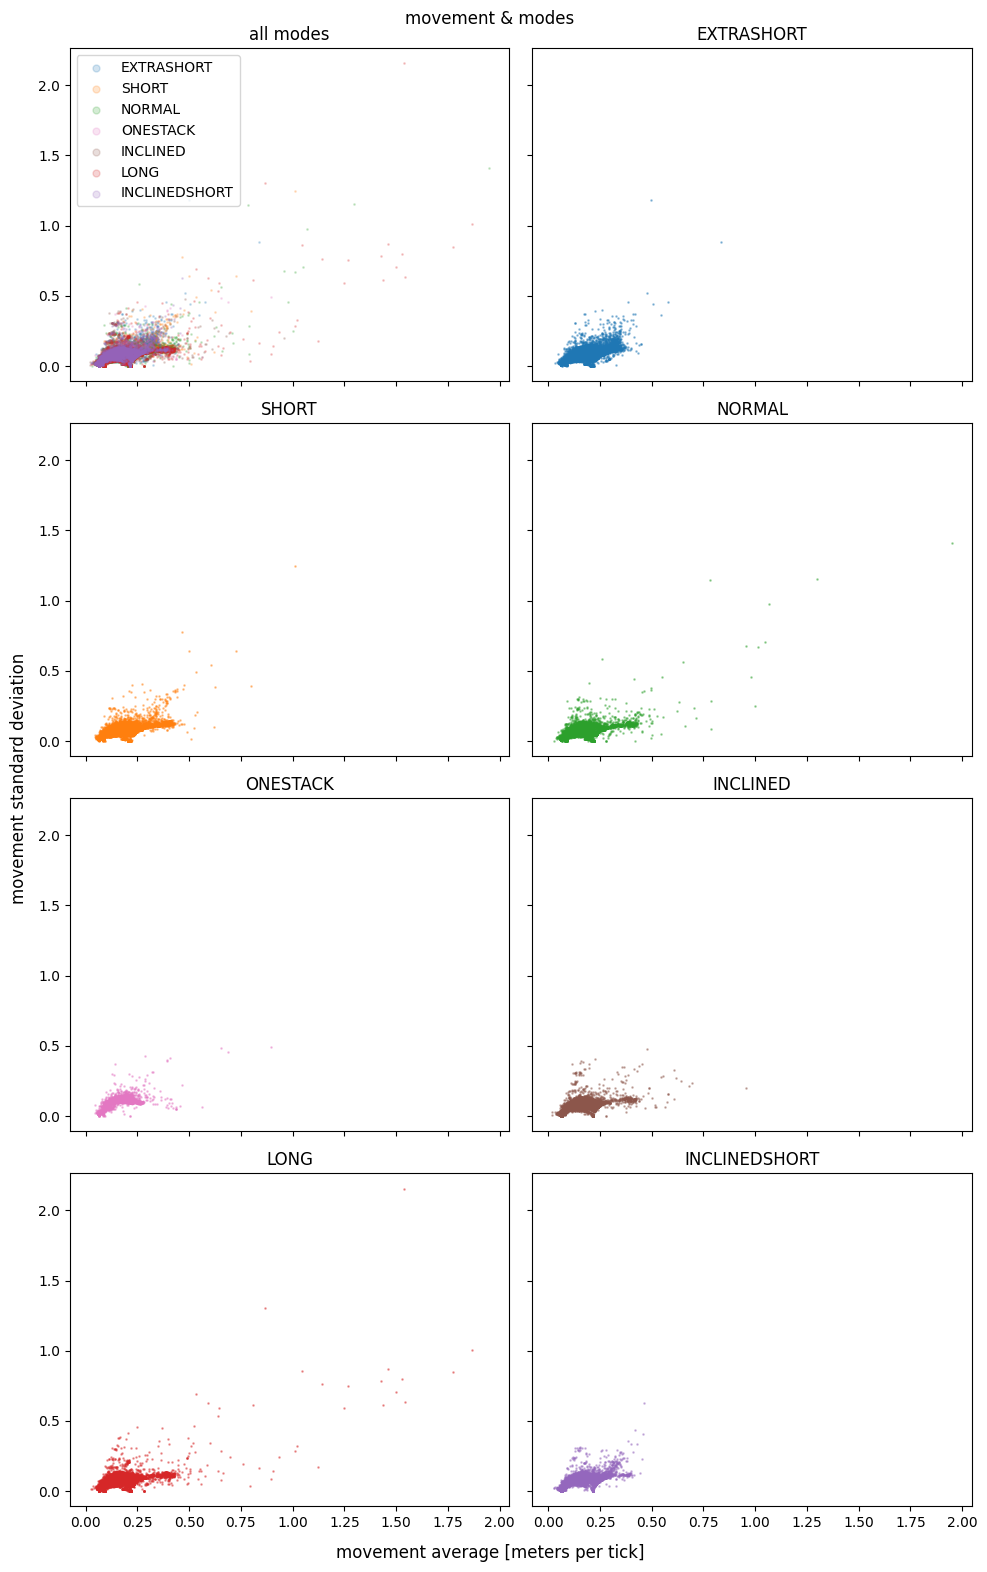

In [4]:
modes_list = df_wide["fastBuilderMode"].unique()
graph_rows = math.ceil((len(modes_list)+1) / 2)

fig, axes = plt.subplots(graph_rows, 2, figsize=(10, 4* graph_rows), sharex=True, sharey=True)
axes = axes.flatten()

movement_columns = df_wide.columns.str.startswith("movement_")
movement_array = df_wide.loc[:, movement_columns].to_numpy()
movement_avg = movement_array.mean(axis=1)
movement_std = movement_array.std(axis=1)

for mode in modes_list:
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    axes[0].scatter(movement_avg[is_mode], movement_std[is_mode], s=1.0, alpha=0.2, label=mode, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))

for ax, mode in zip(axes[1:], modes_list):
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    ax.scatter(movement_avg[is_mode], movement_std[is_mode], s=0.8, alpha=0.4, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))
    ax.set_title(mode)

axes[0].legend(markerscale=5)
axes[0].set_title("all modes")
fig.supxlabel("movement average [meters per tick]")
fig.supylabel("movement standard deviation")
fig.suptitle("movement & modes")
fig.tight_layout()

plt.show()

## 02 - camera movement & modes

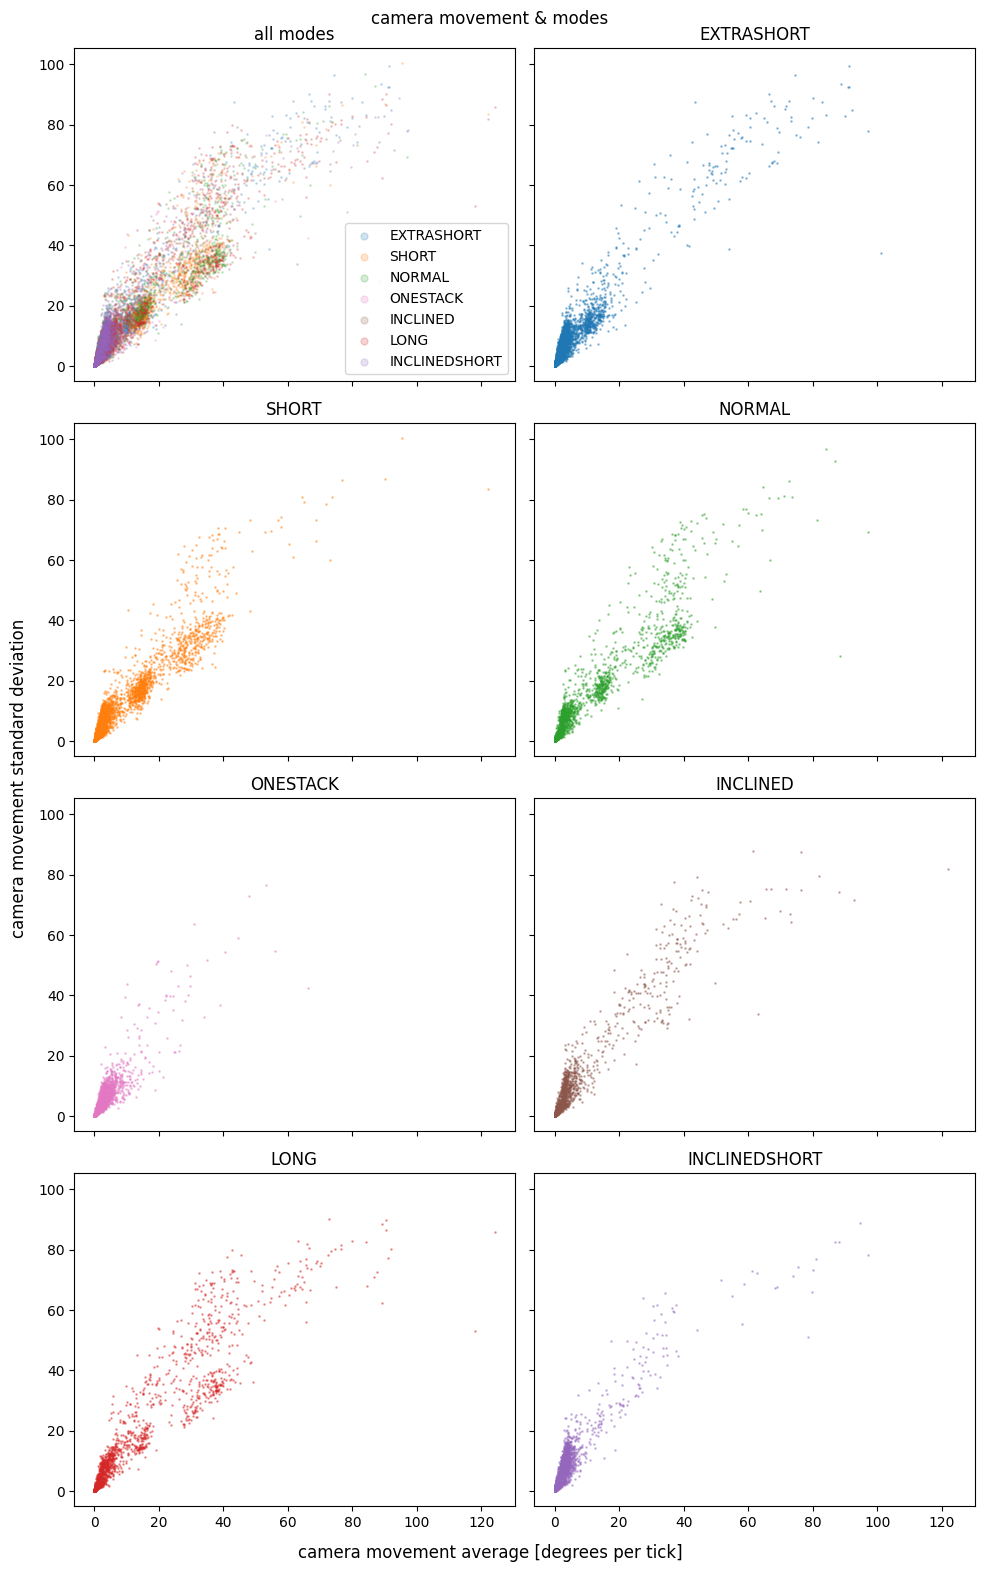

In [5]:
modes_list = df_wide["fastBuilderMode"].unique()
graph_rows = math.ceil((len(modes_list)+1) / 2)

fig, axes = plt.subplots(graph_rows, 2, figsize=(10, 4* graph_rows), sharex=True, sharey=True)
axes = axes.flatten()

yaw_columns = df_wide.columns.str.startswith("yaw_change_")
pitch_columns = df_wide.columns.str.startswith("pitch_change_")
yaw_array = df_wide.loc[:, yaw_columns].to_numpy()
pitch_array = df_wide.loc[:, pitch_columns].to_numpy()

turn_array = np.hypot(yaw_array, pitch_array)
turn_avg = turn_array.mean(axis=1)
turn_std = turn_array.std(axis=1)

for mode in modes_list:
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    axes[0].scatter(turn_avg[is_mode], turn_std[is_mode], s=1.0, alpha=0.2, label=mode, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))

for ax, mode in zip(axes[1:], modes_list):
    is_mode = (df_wide["fastBuilderMode"] == mode).to_numpy()
    ax.scatter(turn_avg[is_mode], turn_std[is_mode], s=0.8, alpha=0.4, color=MODE_COLORS.get(mode, DEFAULT_MODE_COLOR))
    ax.set_title(mode)

axes[0].legend(markerscale=5)
axes[0].set_title("all modes")
fig.supxlabel("camera movement average [degrees per tick]")
fig.supylabel("camera movement standard deviation")
fig.suptitle("camera movement & modes")
fig.tight_layout()

plt.show()

## 03 - clustering movement & camera

#### plot settings

In [6]:
CLUSTER_COUNT = 5
CLUSTER_FEATURES = ["movement_avg", "movement_std", "turn_avg_log"]

OUTLIER_PERCENTILE = 99

#### create dataframe

In [7]:
df_clustering = pd.DataFrame({
    "idAnonymous": df_wide["idAnonymous"],
    "fastBuilderMode": df_wide["fastBuilderMode"],
    "movement_avg": movement_avg,
    "movement_std": movement_std,
    "turn_avg_log": np.log1p(turn_avg),
})

#### camera movement histogram

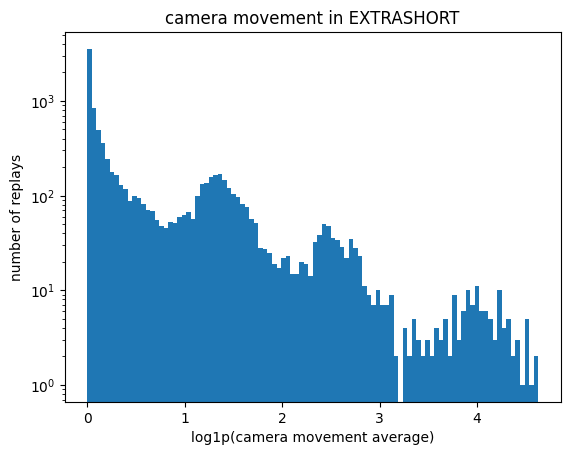

In [8]:
is_mode = df_clustering["fastBuilderMode"] == "EXTRASHORT"
df_clustering_extrashort = df_clustering[is_mode]

plt.hist(df_clustering_extrashort["turn_avg_log"], bins=100)
plt.xlabel("log1p(camera movement average)")
plt.yscale("log")
plt.ylabel("number of replays")
plt.title("camera movement in EXTRASHORT")
plt.show()

#### 3d plot


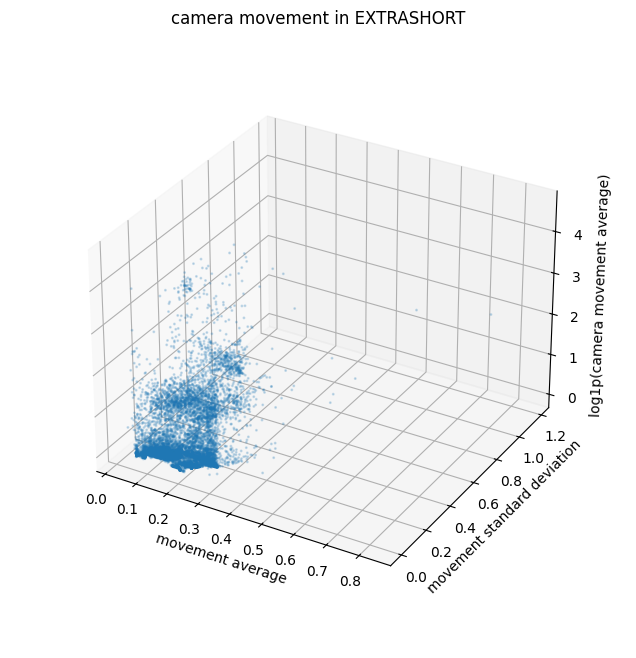

In [9]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    df_clustering_extrashort["movement_avg"],
    df_clustering_extrashort["movement_std"],
    df_clustering_extrashort["turn_avg_log"],
    s=1.2,
    alpha=0.2
)
ax.set_xlabel("movement average")
ax.set_ylabel("movement standard deviation")
ax.set_zlabel("log1p(camera movement average)")
ax.set_title("camera movement in EXTRASHORT")
ax.set_box_aspect(None, zoom=0.85)
plt.show()


#### 2d scatter of 3d plot

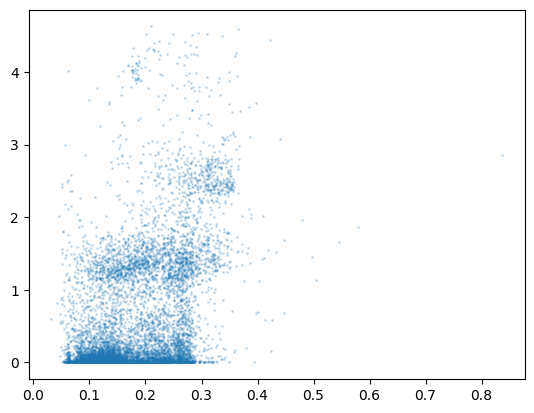

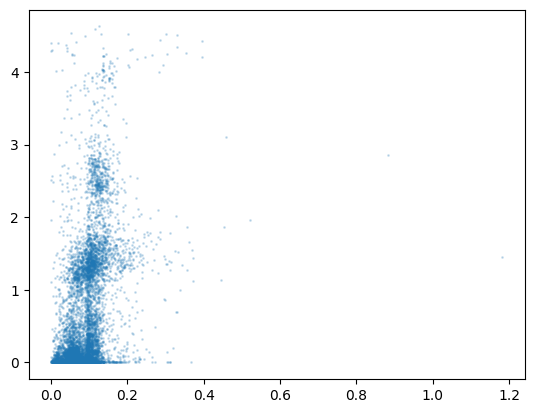

In [10]:
plt.scatter(df_clustering_extrashort["movement_avg"], df_clustering_extrashort["turn_avg_log"], s=1.0, alpha=0.2)
plt.show()
plt.scatter(df_clustering_extrashort["movement_std"], df_clustering_extrashort["turn_avg_log"], s=1.0, alpha=0.2)
plt.show()


#### scaling

In [11]:
features_extrashort = df_clustering_extrashort[CLUSTER_FEATURES]
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_extrashort)

print(features_scaled.shape, features_scaled.mean(axis=0))
print(features_scaled.std(axis=0))

(9495, 3) [ 2.20010073e-16 -9.39158645e-17 -7.18400238e-17]
[1. 1. 1.]


#### k-means clustering

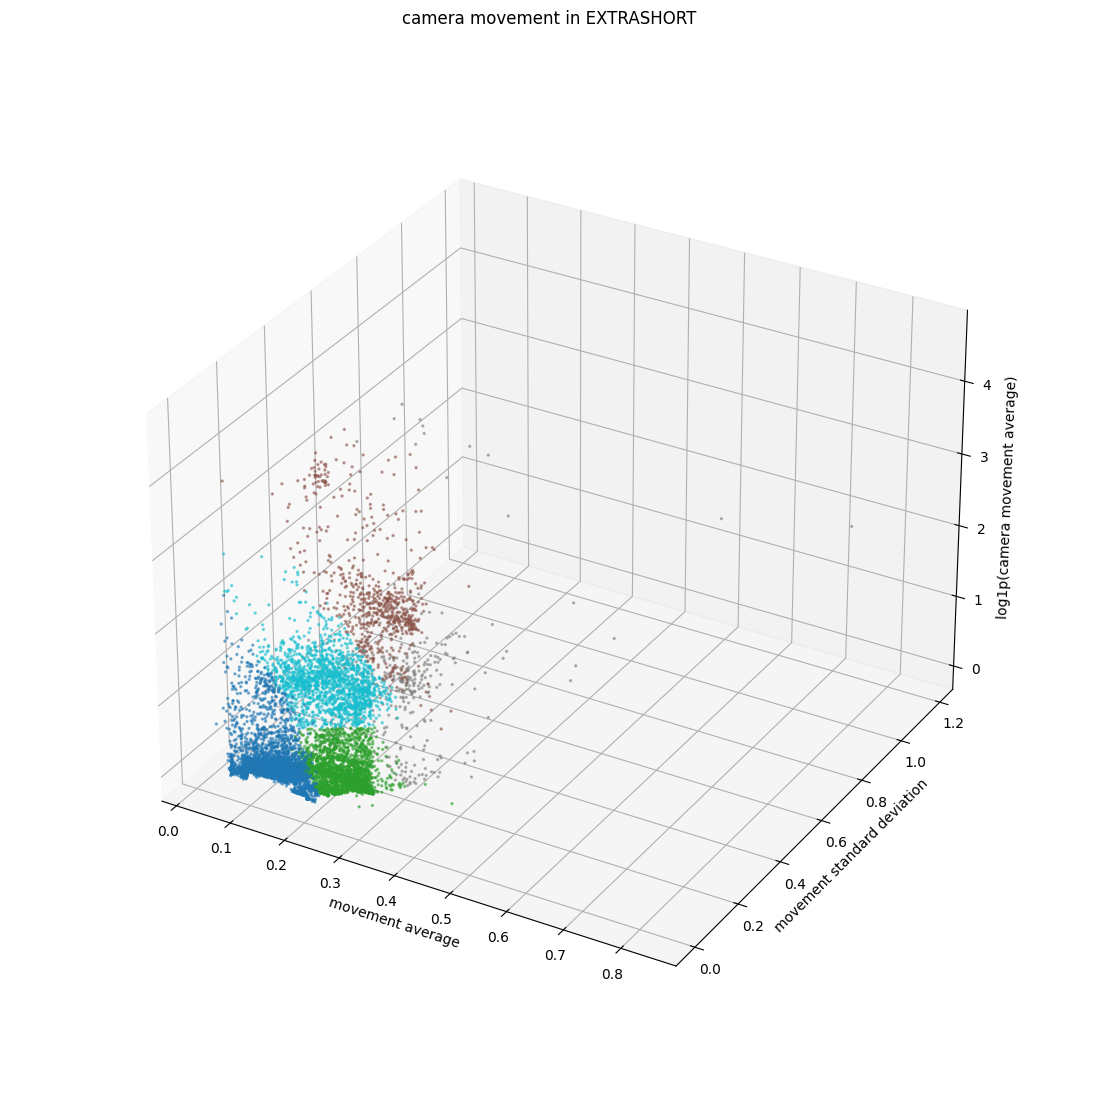

In [12]:
kmeans = KMeans(n_clusters=CLUSTER_COUNT, random_state=RANDOM_SEED)
cluster_labels = kmeans.fit_predict(features_scaled)

fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    df_clustering_extrashort["movement_avg"],
    df_clustering_extrashort["movement_std"],
    df_clustering_extrashort["turn_avg_log"],
    c=cluster_labels,
    cmap="tab10",
    s=2.0,
    alpha=0.5
)
ax.set_xlabel("movement average")
ax.set_ylabel("movement standard deviation")
ax.set_zlabel("log1p(camera movement average)")
ax.set_title("camera movement in EXTRASHORT")
ax.set_box_aspect(None, zoom=0.85)
plt.show()

#### choosing k

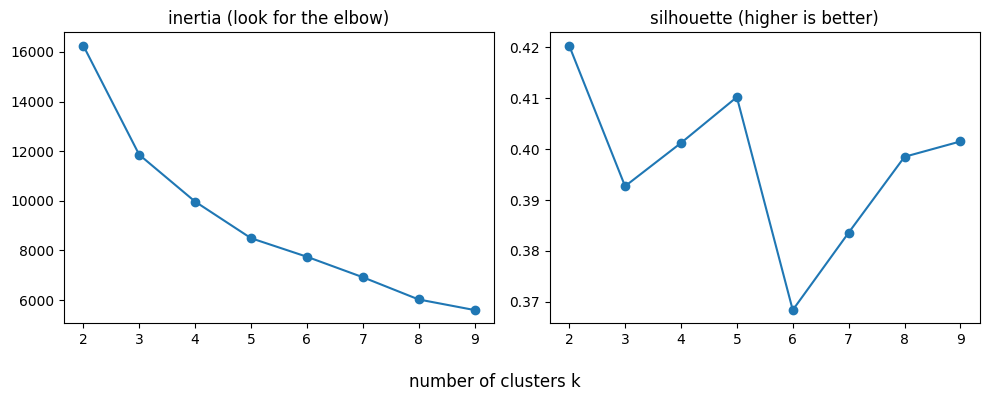

In [13]:
k_values = range(2, 10)
inertias = []
silhouettes = []

for k in k_values:
    kmeans_test = KMeans(n_clusters=k, random_state=RANDOM_SEED)
    labels_test = kmeans_test.fit_predict(features_scaled)
    inertias.append(kmeans_test.inertia_)
    silhouettes.append(silhouette_score(features_scaled, labels_test))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("inertia (look for the elbow)")
axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_title("silhouette (higher is better)")
fig.supxlabel("number of clusters k")
fig.tight_layout()
plt.show()

#### outliers

threshold: 2.39
outliers: 95


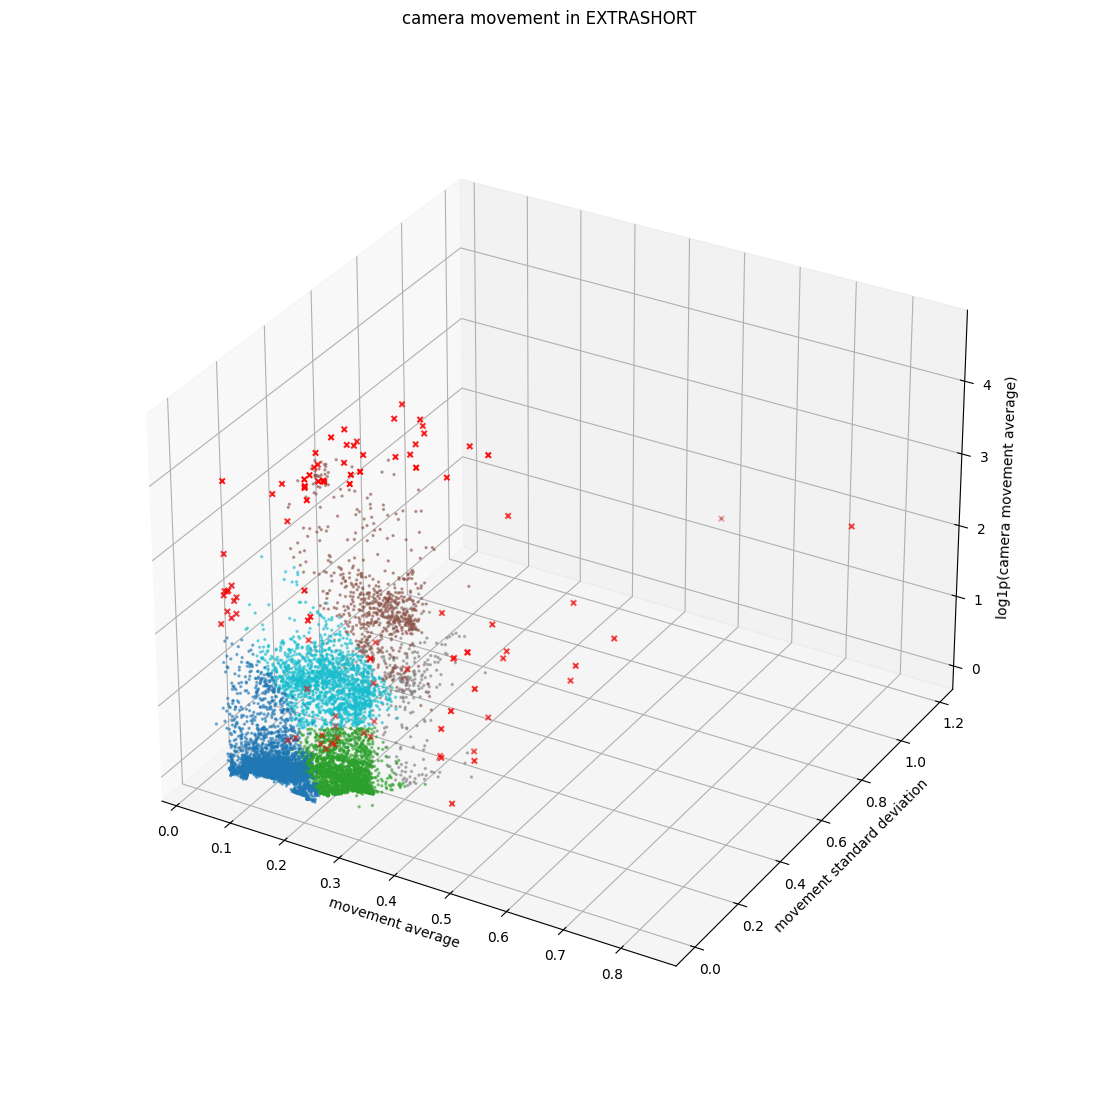

In [14]:
center_distances = kmeans.transform(features_scaled).min(axis=1)
outlier_threshold = np.percentile(center_distances, OUTLIER_PERCENTILE)
is_outlier = center_distances > outlier_threshold

print(f"threshold: {outlier_threshold:.2f}")
print(f"outliers: {is_outlier.sum()}")

outlier_rows = df_clustering_extrashort[is_outlier]

fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    df_clustering_extrashort["movement_avg"],
    df_clustering_extrashort["movement_std"],
    df_clustering_extrashort["turn_avg_log"],
    c=cluster_labels,
    cmap="tab10",
    s=2.0,
    alpha=0.5
)

ax.scatter(
    outlier_rows["movement_avg"],
    outlier_rows["movement_std"],
    outlier_rows["turn_avg_log"],
    color="red", marker="x", s=15
)
ax.set_xlabel("movement average")
ax.set_ylabel("movement standard deviation")
ax.set_zlabel("log1p(camera movement average)")
ax.set_title("camera movement in EXTRASHORT")
ax.set_box_aspect(None, zoom=0.85)

plt.show()

## 03b - clustering movement & camera (all modes)

#### settings

In [89]:
CLUSTER_ELBOW_K_VALUES = range(2, 16)
CLUSTER_OUTLIER_PERCENTILE = 99

CLUSTER_COUNTS = {
    "EXTRASHORT": 11,
    "SHORT": 11,
    "NORMAL": 11,
    "LONG": 9,
    "ONESTACK": 11,
    "INCLINED": 8,
    "INCLINEDSHORT": 9,
}

CLUSTER_EXPORT_PATH = EXPORT_DIR / "cluster_export_movement_camera.csv"

#### preparations

In [61]:
def scale(df_mode, features):
    scaler = StandardScaler()
    scaled = scaler.fit_transform(df_mode[features])
    return scaler, scaled

clustering_results = {}
for mode in df_clustering["fastBuilderMode"].unique():
    df_mode = df_clustering[df_clustering["fastBuilderMode"] == mode]
    scaler, scaled = scale(df_mode, CLUSTER_FEATURES)
    clustering_results[mode] = {
        "ids": df_mode["idAnonymous"].to_numpy(),
        "features": df_mode[CLUSTER_FEATURES].to_numpy(),
        "scaler": scaler,
        "scaled": scaled,
    }
    print(f"{mode}: {len(df_mode)} replays")


EXTRASHORT: 9495 replays
SHORT: 9944 replays
NORMAL: 9988 replays
ONESTACK: 9983 replays
INCLINED: 9976 replays
LONG: 9987 replays
INCLINEDSHORT: 9928 replays


#### elbow & silhouette plots

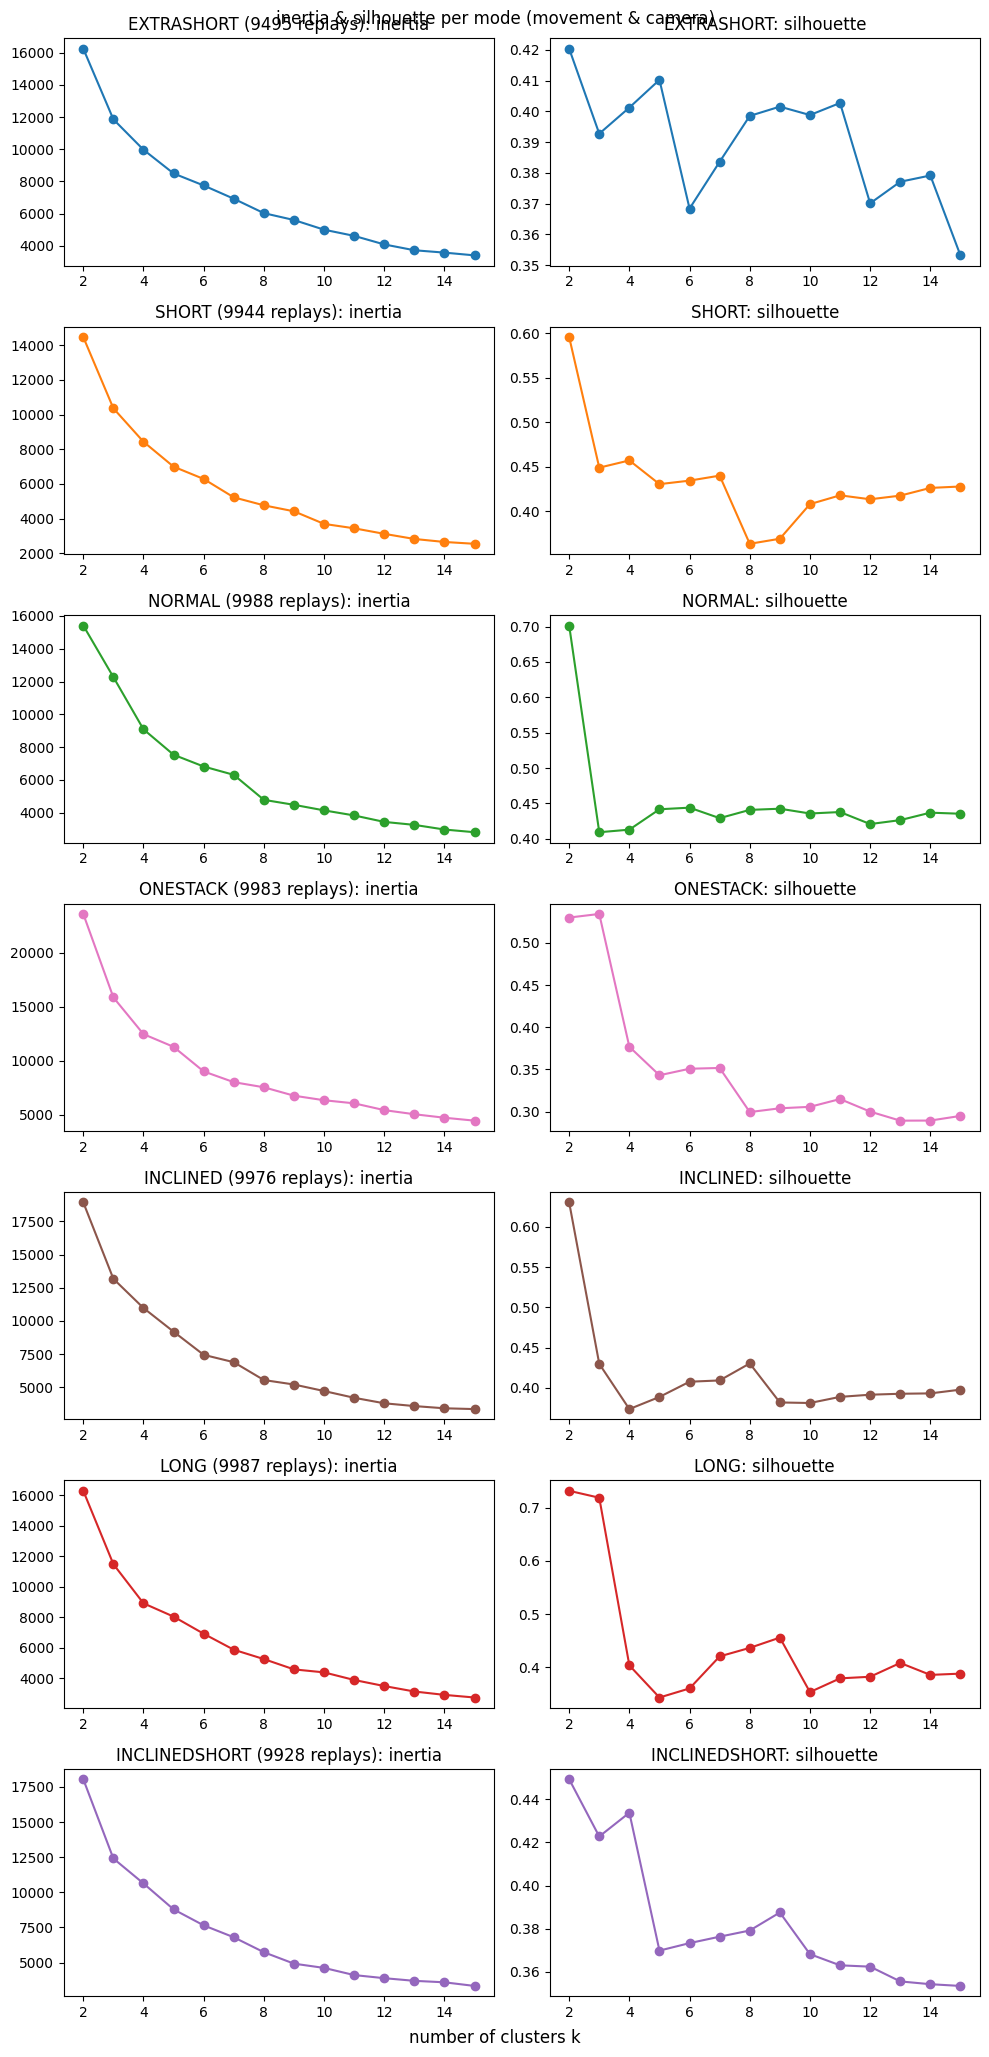

In [62]:
def cluster_scores(scaled, k_values):
    inertias = []
    silhouettes = []
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=RANDOM_SEED)
        labels = km.fit_predict(scaled)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(scaled, labels))
    return inertias, silhouettes

modes_list = list(clustering_results)
graph_rows = len(modes_list)

fig, axes = plt.subplots(graph_rows, 2, figsize=(10, 3 * graph_rows))
for row, mode in enumerate(modes_list):
    inertias, silhouettes = cluster_scores(clustering_results[mode]["scaled"], CLUSTER_ELBOW_K_VALUES)
    color = MODE_COLORS.get(mode, DEFAULT_MODE_COLOR)
    replay_count = len(clustering_results[mode]["ids"])

    axes[row, 0].plot(CLUSTER_ELBOW_K_VALUES, inertias, marker="o", color=color)
    axes[row, 0].set_title(f"{mode} ({replay_count} replays): inertia")
    axes[row, 1].plot(CLUSTER_ELBOW_K_VALUES, silhouettes, marker="o", color=color)
    axes[row, 1].set_title(f"{mode}: silhouette")

fig.supxlabel("number of clusters k")
fig.suptitle("inertia & silhouette per mode (movement & camera)")
fig.tight_layout()
plt.show()

| mode          | k-value old | k-value new (10k + r18) |
|---------------|-------------|-------------------------|
| EXTRASHORT    | 6           | 11                      |
| SHORT         | 4           | 11                      |
| NORMAL        | 8           | 11                      |
| LONG          | 6           | 9                       |
| INCLINEDSHORT | 8           | 9                       |
| INCLINED      | 6           | 8                       |
| ONESTACK      | 7           | 11                      |

#### k-means

In [63]:
for mode, result in clustering_results.items():
    kmeans = KMeans(n_clusters=CLUSTER_COUNTS[mode], random_state=RANDOM_SEED)
    labels = kmeans.fit_predict(result["scaled"])
    nearest_distances = kmeans.transform(result["scaled"]).min(axis=1)
    threshold = np.percentile(nearest_distances, CLUSTER_OUTLIER_PERCENTILE)

    result["kmeans"] = kmeans
    result["labels"] = labels
    result["nearest_distances"] = nearest_distances
    result["is_outlier"] = nearest_distances > threshold


    print(f"{mode}: k={kmeans.n_clusters}, cluster sizes{np.bincount(labels).tolist()}, outliers {result['is_outlier'].sum()}")

EXTRASHORT: k=11, cluster sizes[3299, 1048, 485, 1278, 1099, 70, 1029, 2, 323, 703, 159], outliers 95
SHORT: k=11, cluster sizes[3089, 528, 1052, 5, 1270, 112, 989, 254, 1293, 483, 869], outliers 100
NORMAL: k=11, cluster sizes[399, 4622, 1377, 4, 572, 65, 1020, 1503, 51, 361, 14], outliers 100
ONESTACK: k=11, cluster sizes[925, 3023, 478, 319, 2471, 11, 1174, 506, 824, 30, 222], outliers 100
INCLINED: k=8, cluster sizes[1746, 275, 1511, 1435, 530, 3640, 62, 777], outliers 100
LONG: k=9, cluster sizes[1043, 607, 14, 2158, 57, 509, 1106, 1, 4492], outliers 100
INCLINEDSHORT: k=9, cluster sizes[1712, 1458, 1048, 3150, 540, 143, 1062, 116, 699], outliers 100


#### 3d plots
(claude generated)

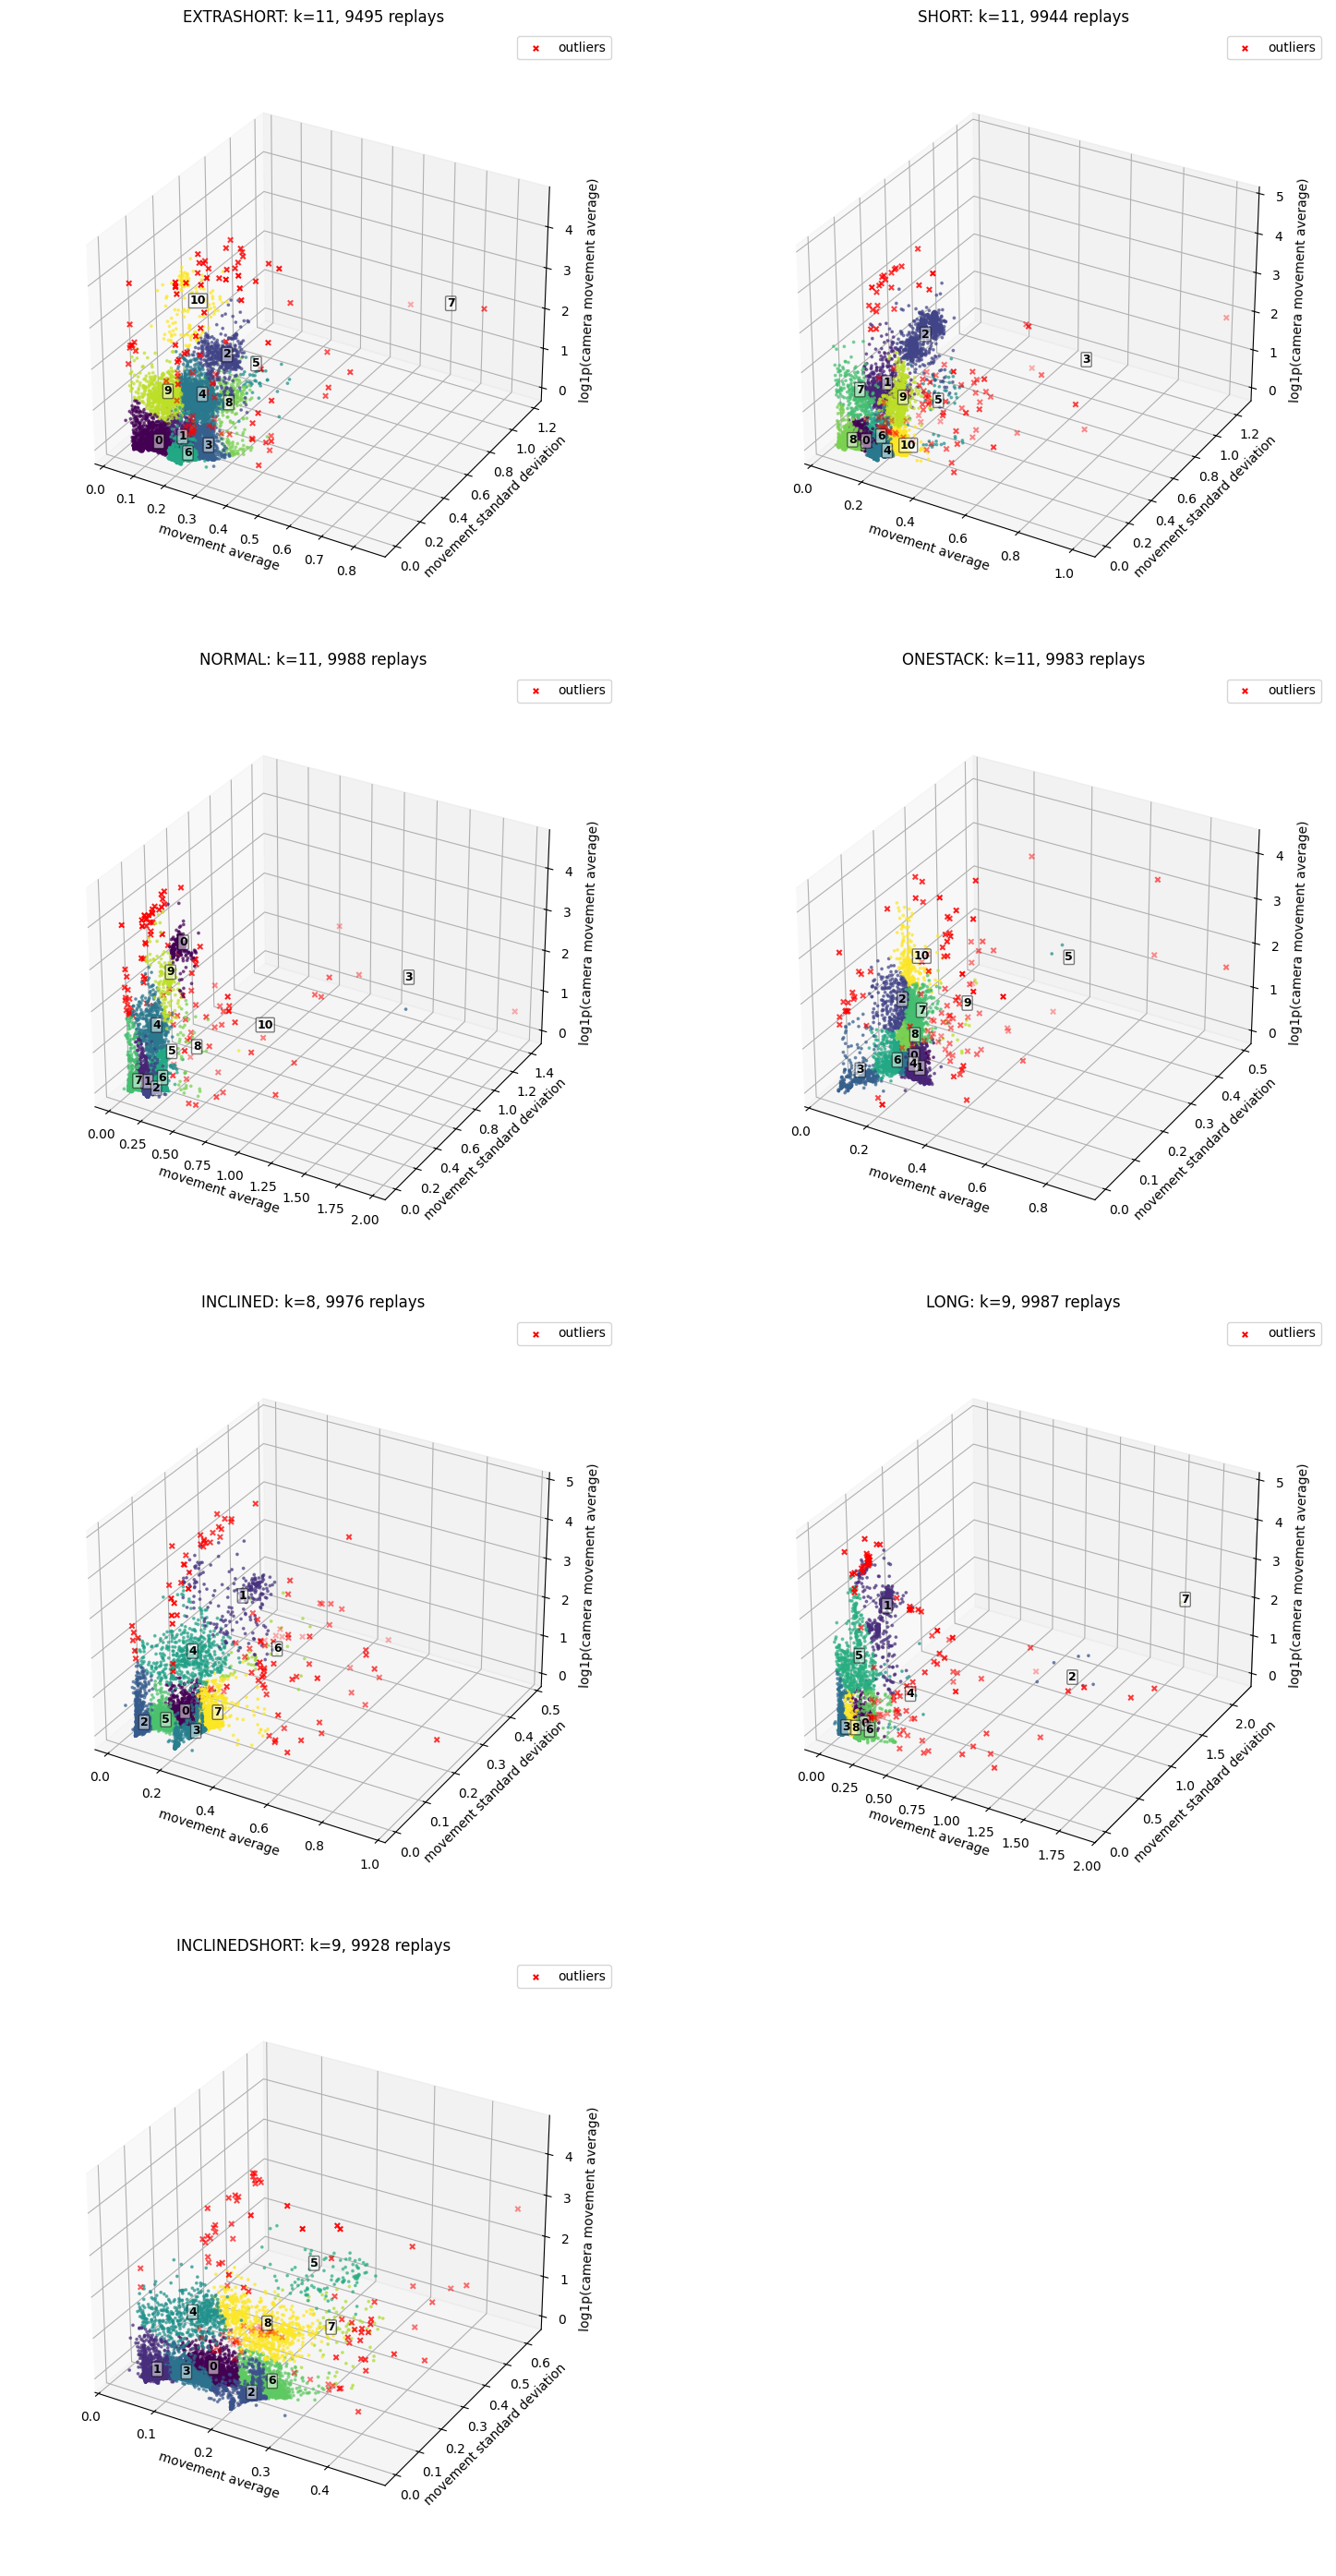

In [65]:
modes_list = list(clustering_results)
graph_rows = math.ceil(len(modes_list) / 2)

fig = plt.figure(figsize=(16, 7 * graph_rows))

for position, mode in enumerate(modes_list, start=1):
    result = clustering_results[mode]
    points = result["features"]
    is_outlier = result["is_outlier"]
    # the centres live in scaled units, so convert them back to the real feature units
    centers = result["scaler"].inverse_transform(result["kmeans"].cluster_centers_)

    ax = fig.add_subplot(graph_rows, 2, position, projection="3d")
    ax.scatter(
        points[~is_outlier, 0], points[~is_outlier, 1], points[~is_outlier, 2],
        c=result["labels"][~is_outlier], cmap="viridis", s=3, alpha=0.6
    )
    ax.scatter(
        points[is_outlier, 0], points[is_outlier, 1], points[is_outlier, 2],
        color="red", marker="x", s=15, label="outliers"
    )

    # cluster number at each centre
    for cluster, center in enumerate(centers):
        ax.text(
            center[0], center[1], center[2], str(cluster),
            color="black", fontsize=9, fontweight="bold", zorder=100,
            bbox=dict(facecolor="white", alpha=0.5, edgecolor="black", boxstyle="round,pad=0.1")
        )

    ax.set_xlabel("movement average")
    ax.set_ylabel("movement standard deviation")
    ax.set_zlabel("log1p(camera movement average)")
    ax.set_title(f"{mode}: k={result['kmeans'].n_clusters}, {len(result['ids'])} replays")
    ax.set_box_aspect(None, zoom=0.85)
    ax.legend()

fig.tight_layout()
plt.show()

#### export

In [90]:
df_cluster_export = cluster_export_rows("movement_camera", clustering_results)
df_cluster_export.to_csv(CLUSTER_EXPORT_PATH, index=False)

print(f"exported {len(df_cluster_export)} rows to {CLUSTER_EXPORT_PATH}")

exported 395 rows to ../data/notebooks_exports/cluster_export_movement_camera.csv


## 04 - mcplayhd concept

#### settings

In [20]:
MCPLAYHD_CLUSTER_COUNT = 24
MCPLAYHD_OUTLIER_PERCENTILE = 99

#### preprocessing

In [21]:
is_extrashort = df_mcplayhd_concept["fastBuilderMode"] == "EXTRASHORT"
df_mcplayhd_extrashort = df_mcplayhd_concept[is_extrashort].drop(columns=["fastBuilderMode", "idAnonymous"])

mcplayhd_scaler = StandardScaler()

mcplayhd_scaled = mcplayhd_scaler.fit_transform(df_mcplayhd_extrashort)

pca = PCA(n_components=0.95, random_state=RANDOM_SEED)
mcplayhd_pca = pca.fit_transform(mcplayhd_scaled)
print(f"--> Reduced dimensions from {mcplayhd_scaled.shape[1]} to {mcplayhd_pca.shape[1]}")

print(pca.explained_variance_ratio_[:10])
print(pca.explained_variance_ratio_.cumsum()[[0, 4, 9, 49, 99]])


--> Reduced dimensions from 545 to 292
[0.1162175  0.0395509  0.02610697 0.02019144 0.01892467 0.0167517
 0.01352647 0.01336148 0.0127826  0.01117627]
[0.1162175  0.22099148 0.28858999 0.57703161 0.77118379]


#### choosing k

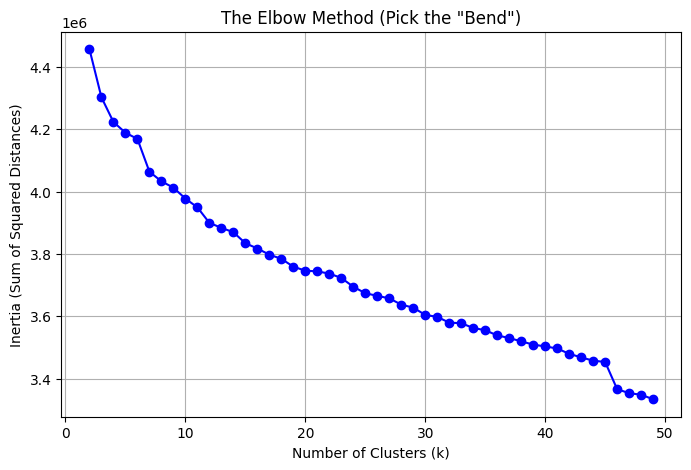

In [22]:
inertias = []
k_range = range(2, 50)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED)
    km.fit(mcplayhd_pca) # Fit on the REDUCED data
    inertias.append(km.inertia_)

# Show Elbow Plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Sum of Squared Distances)')
plt.title('The Elbow Method (Pick the "Bend")')
plt.grid(True)
plt.show()

nothing really stands out as an elbow, we take 24

#### extract replays

In [23]:
mcplayhd_kmeans = KMeans(n_clusters=MCPLAYHD_CLUSTER_COUNT, random_state=RANDOM_SEED)
mcplayhd_labels = mcplayhd_kmeans.fit_predict(mcplayhd_pca)
print(np.bincount(mcplayhd_labels))

mcplayhd_distances = mcplayhd_kmeans.transform(mcplayhd_pca)

archetype_positions = []
for cluster in range(MCPLAYHD_CLUSTER_COUNT):
    cluster_positions = np.where(mcplayhd_labels == cluster)[0]
    distances = mcplayhd_distances[cluster_positions, cluster]
    archetype_positions.append(cluster_positions[distances.argmin()])

archetype_ids = df_mcplayhd_concept[is_extrashort]["idAnonymous"].iloc[archetype_positions]
print(archetype_ids.to_list())



[ 831 1285  319  234  391  502  179  499  422    9   77  582    1  686
  397  328  398  414  519  633  278  331  174    9]
[399028, 411528, 65433, 350771, 55819, 238493, 378180, 408001, 96801, 316505, 133461, 318259, 206096, 322197, 62135, 489754, 92604, 332900, 128030, 253347, 87070, 106784, 324283, 303681]


#### outliers

In [24]:
nearest_center_distances = mcplayhd_distances.min(axis=1)
mcplayhd_threshold = np.percentile(nearest_center_distances, MCPLAYHD_OUTLIER_PERCENTILE)
is_mcplayhd_outlier = nearest_center_distances > mcplayhd_threshold

print(f"threshold: {mcplayhd_threshold:.2f}")
print(f"outliers: {is_mcplayhd_outlier.sum()}")

extrashort_ids = df_mcplayhd_concept[is_extrashort]["idAnonymous"]
outlier_ids = extrashort_ids[is_mcplayhd_outlier]
print(f"extrashort outliers: {len(outlier_ids)}")

outlier_distances = nearest_center_distances[is_mcplayhd_outlier]
order = np.argsort(outlier_distances)[::-1]
print(outlier_ids.iloc[order].to_list())


threshold: 54.18
outliers: 95
extrashort outliers: 95
[290846, 418825, 326659, 215118, 112463, 274221, 350025, 13924, 367757, 221857, 400981, 325244, 346551, 205541, 85529, 326010, 327902, 380760, 331805, 455691, 147860, 287397, 242826, 83734, 39002, 197109, 325725, 465657, 215076, 486416, 363278, 429814, 327880, 401000, 404367, 319519, 119254, 194485, 198028, 65914, 11696, 163219, 390993, 450685, 127884, 468455, 174344, 308661, 332379, 483193, 291515, 279356, 301191, 265424, 342759, 294307, 492186, 275934, 77744, 83949, 172912, 107244, 115370, 152039, 116641, 368877, 450207, 234616, 155179, 476743, 413446, 339728, 361637, 354358, 336592, 70693, 401332, 415714, 440796, 51836, 440398, 372698, 301747, 330847, 404030, 341205, 421958, 348772, 181020, 250602, 284549, 41330, 397402, 237523, 444182]


#### 3d plot of the first 3 components
(claude generated)

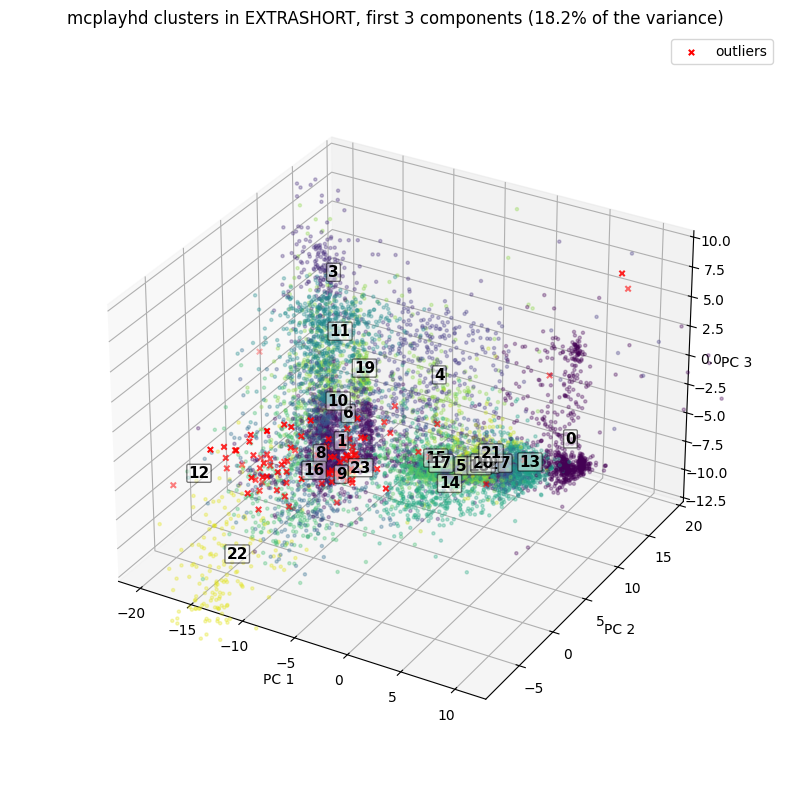

In [25]:
pc_share = pca.explained_variance_ratio_[:3].sum()
normal_points = mcplayhd_pca[~is_mcplayhd_outlier]
outlier_points = mcplayhd_pca[is_mcplayhd_outlier]

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    normal_points[:, 0],
    normal_points[:, 1],
    normal_points[:, 2],
    c=mcplayhd_labels[~is_mcplayhd_outlier],
    cmap="viridis",
    s=5,
    alpha=0.3
)
ax.scatter(
    outlier_points[:, 0],
    outlier_points[:, 1],
    outlier_points[:, 2],
    color="red", marker="x", s=15, label="outliers"
)

# cluster number at each centre
for cluster, center in enumerate(mcplayhd_kmeans.cluster_centers_):
    ax.text(
        center[0], center[1], center[2], str(cluster),
        color="black", fontsize=11, fontweight="bold", zorder=100,
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="black", boxstyle="round,pad=0.1")
    )

# zoom to the middle 99% of the replays, the far outliers would squash the plot
x_min, x_max = np.percentile(mcplayhd_pca[:, 0], [0.5, 99.5])
y_min, y_max = np.percentile(mcplayhd_pca[:, 1], [0.5, 99.5])
z_min, z_max = np.percentile(mcplayhd_pca[:, 2], [0.5, 99.5])
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_zlim(z_min, z_max)

ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_zlabel("PC 3")
ax.set_title(f"mcplayhd clusters in EXTRASHORT, first 3 components ({pc_share:.1%} of the variance)")
ax.set_box_aspect(None, zoom=0.85)
ax.legend()
plt.show()

## 04b - mcplayhd concept (all modes)

#### settings

In [96]:
ELBOW_K_VALUES = range(2, 41, 2)

MCPLAYHD_OUTLIER_PERCENTILE = 99

MCPLAYHD_CLUSTER_COUNTS = {
    "EXTRASHORT": 20,
    "SHORT": 20,
    "NORMAL": 24,
    "LONG": 24,
    "ONESTACK": 22,
    "INCLINED": 22,
    "INCLINEDSHORT": 22,
}

MCPLAYHD_EXPORT_PATH = EXPORT_DIR / "cluster_export_mcplayhd_concept.csv"

#### preparations

In [97]:
def scale_and_reduce(df_mode):
    features = df_mode.drop(columns=["fastBuilderMode", "idAnonymous"])
    scaler = StandardScaler()
    scaled = scaler.fit_transform(features)
    pca = PCA(n_components=0.95, random_state=RANDOM_SEED)
    reduced = pca.fit_transform(scaled)
    return scaler, pca, reduced

# loop to prepare data per mode
mcplayhd_results = {}
for mode in df_mcplayhd_concept["fastBuilderMode"].unique():
    df_mode = df_mcplayhd_concept[df_mcplayhd_concept["fastBuilderMode"] == mode]
    scaler, pca, reduced = scale_and_reduce(df_mode)
    mcplayhd_results[mode] = {
        "ids": df_mode["idAnonymous"].to_numpy(),
        "scaler": scaler,
        "pca": pca,
        "reduced": reduced,
    }
    print(f"{mode}: {len(df_mode)} replays, {reduced.shape[1]} dimensions")

def cluster_scores(reduced, k_values):
    inertias = []
    silhouettes = []
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=RANDOM_SEED)
        labels = km.fit_predict(reduced)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(reduced, labels))
    return inertias, silhouettes

EXTRASHORT: 9498 replays, 292 dimensions
SHORT: 9938 replays, 276 dimensions
NORMAL: 9943 replays, 265 dimensions
ONESTACK: 9954 replays, 281 dimensions
INCLINED: 9907 replays, 268 dimensions
LONG: 9842 replays, 270 dimensions
INCLINEDSHORT: 9923 replays, 273 dimensions


#### elbow & silhouettes plots

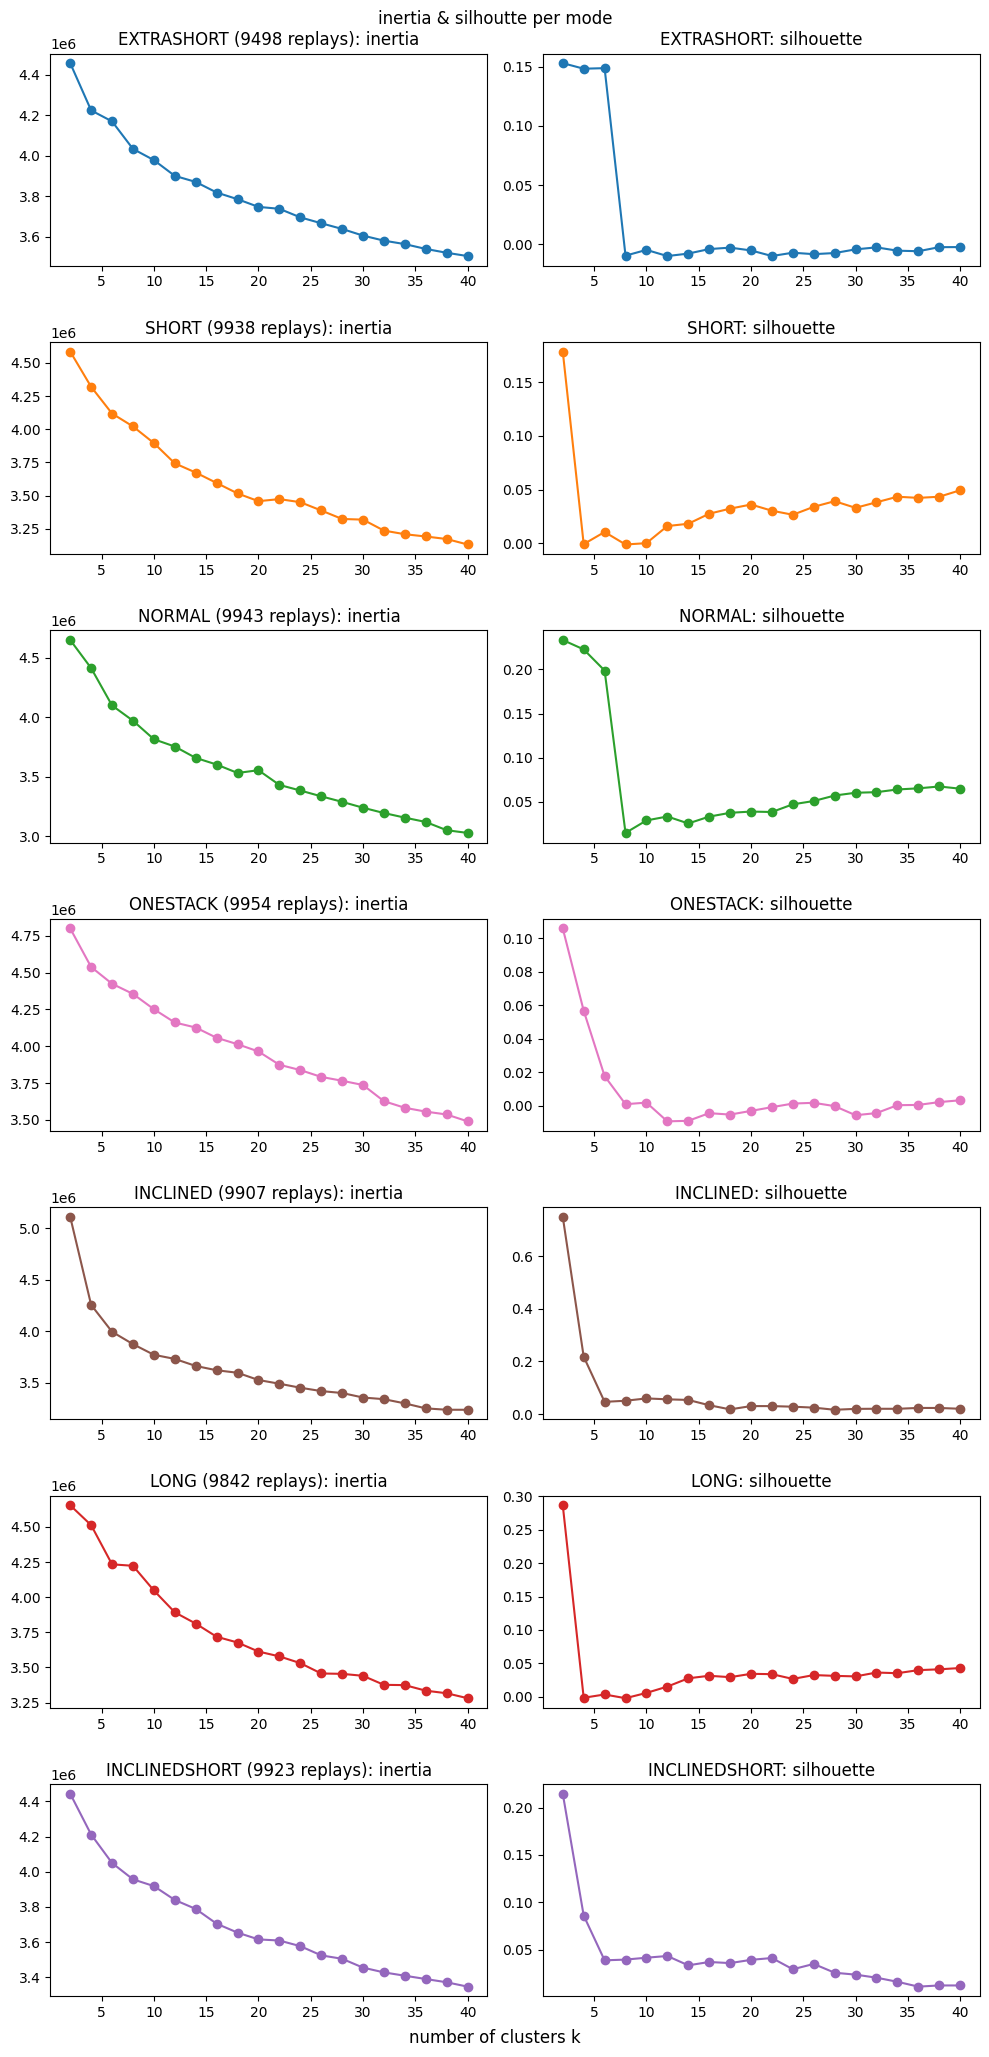

In [100]:
modes_list = list(mcplayhd_results)
graph_rows = len(modes_list)

fig, axes = plt.subplots(graph_rows, 2, figsize=(10, 3 * graph_rows))

for row, mode in enumerate(modes_list):
    inertias, silhouettes = cluster_scores(mcplayhd_results[mode]["reduced"], ELBOW_K_VALUES)
    color = MODE_COLORS.get(mode, DEFAULT_MODE_COLOR)
    replay_count = len(mcplayhd_results[mode]['ids'])

    axes[row, 0].plot(ELBOW_K_VALUES, inertias, marker="o", color=color)
    axes[row, 0].set_title(f"{mode} ({replay_count} replays): inertia")
    axes[row, 1].plot(ELBOW_K_VALUES, silhouettes, marker="o", color=color)
    axes[row, 1].set_title(f"{mode}: silhouette")


fig.supxlabel("number of clusters k")
fig.suptitle("inertia & silhoutte per mode")
fig.tight_layout()
plt.show()

we extract following values:
- extrashort -> 24
- short -> 24
- normal -> 22
- long -> 6
- onestack -> 6
- inclined -> 8
- inclinedshort -> 8

With the knowledge that extrashort, short, normal and long are technically the same mode with just different distanced and input data, it seems desirable to use similar values. The exception for now is long as there is just too few data in this data set to give it a similar value, we might change that later once there is more data. The same applies for inclined and inclinedshort. Onestack is a unique mode. Furthermore, we don't want to go with just 2 or 4 for k. Although it might have the best scores, the purpose of this project is to distinguish between more than just 2 or 4 clusters.

**UPDATE**
new values after adding the sampled data set that has 10k data for each mode

| mode          | k-value old | k-value new (10k + r18) |
|---------------|-------------|-------------------------|
| EXTRASHORT    | 24          | 20                      |
| SHORT         | 24          | 20                      |
| NORMAL        | 22          | 24                      |
| LONG          | 6           | 24                       |
| INCLINEDSHORT | 8           | 22                       |
| INCLINED      | 8           | 22                       |
| ONESTACK      | 6           | 22                      |

#### k-means

In [101]:
for mode, result in mcplayhd_results.items():
    kmeans = KMeans(n_clusters=MCPLAYHD_CLUSTER_COUNTS[mode], random_state=RANDOM_SEED)
    labels = kmeans.fit_predict(result["reduced"])
    nearest_distances = kmeans.transform(result["reduced"]).min(axis=1)
    threshold = np.percentile(nearest_distances, MCPLAYHD_OUTLIER_PERCENTILE)

    result["kmeans"] = kmeans
    result["labels"] = labels
    result["nearest_distances"] = nearest_distances
    result["is_outlier"] = nearest_distances > threshold

    print(f"{mode}: k={kmeans.n_clusters}, cluster sizes{np.bincount(labels).tolist()}, outliers {result['is_outlier'].sum()}")

EXTRASHORT: k=20, cluster sizes[858, 101, 796, 63, 498, 97, 502, 247, 584, 1083, 746, 10, 67, 199, 587, 910, 514, 431, 697, 508], outliers 95
SHORT: k=20, cluster sizes[629, 1181, 887, 775, 53, 244, 205, 1, 343, 1037, 140, 621, 797, 147, 233, 1196, 916, 343, 58, 132], outliers 100
NORMAL: k=24, cluster sizes[651, 269, 57, 1036, 64, 377, 1650, 43, 353, 130, 644, 451, 152, 16, 37, 47, 119, 597, 172, 1, 286, 760, 1331, 700], outliers 100
ONESTACK: k=22, cluster sizes[442, 630, 845, 242, 658, 102, 309, 434, 688, 2, 1, 1370, 541, 155, 617, 1, 712, 670, 441, 1, 544, 549], outliers 100
INCLINED: k=22, cluster sizes[2, 1460, 418, 505, 189, 660, 645, 663, 327, 146, 497, 227, 112, 2, 668, 30, 545, 221, 372, 1352, 470, 396], outliers 100
LONG: k=24, cluster sizes[635, 667, 508, 19, 289, 759, 82, 113, 242, 509, 141, 232, 66, 225, 1382, 73, 703, 286, 442, 387, 1495, 388, 198, 1], outliers 99
INCLINEDSHORT: k=22, cluster sizes[1936, 229, 679, 299, 325, 311, 422, 380, 1, 1, 574, 214, 438, 1257, 337, 

#### 3d plots of the first 3 components
(claude generated)

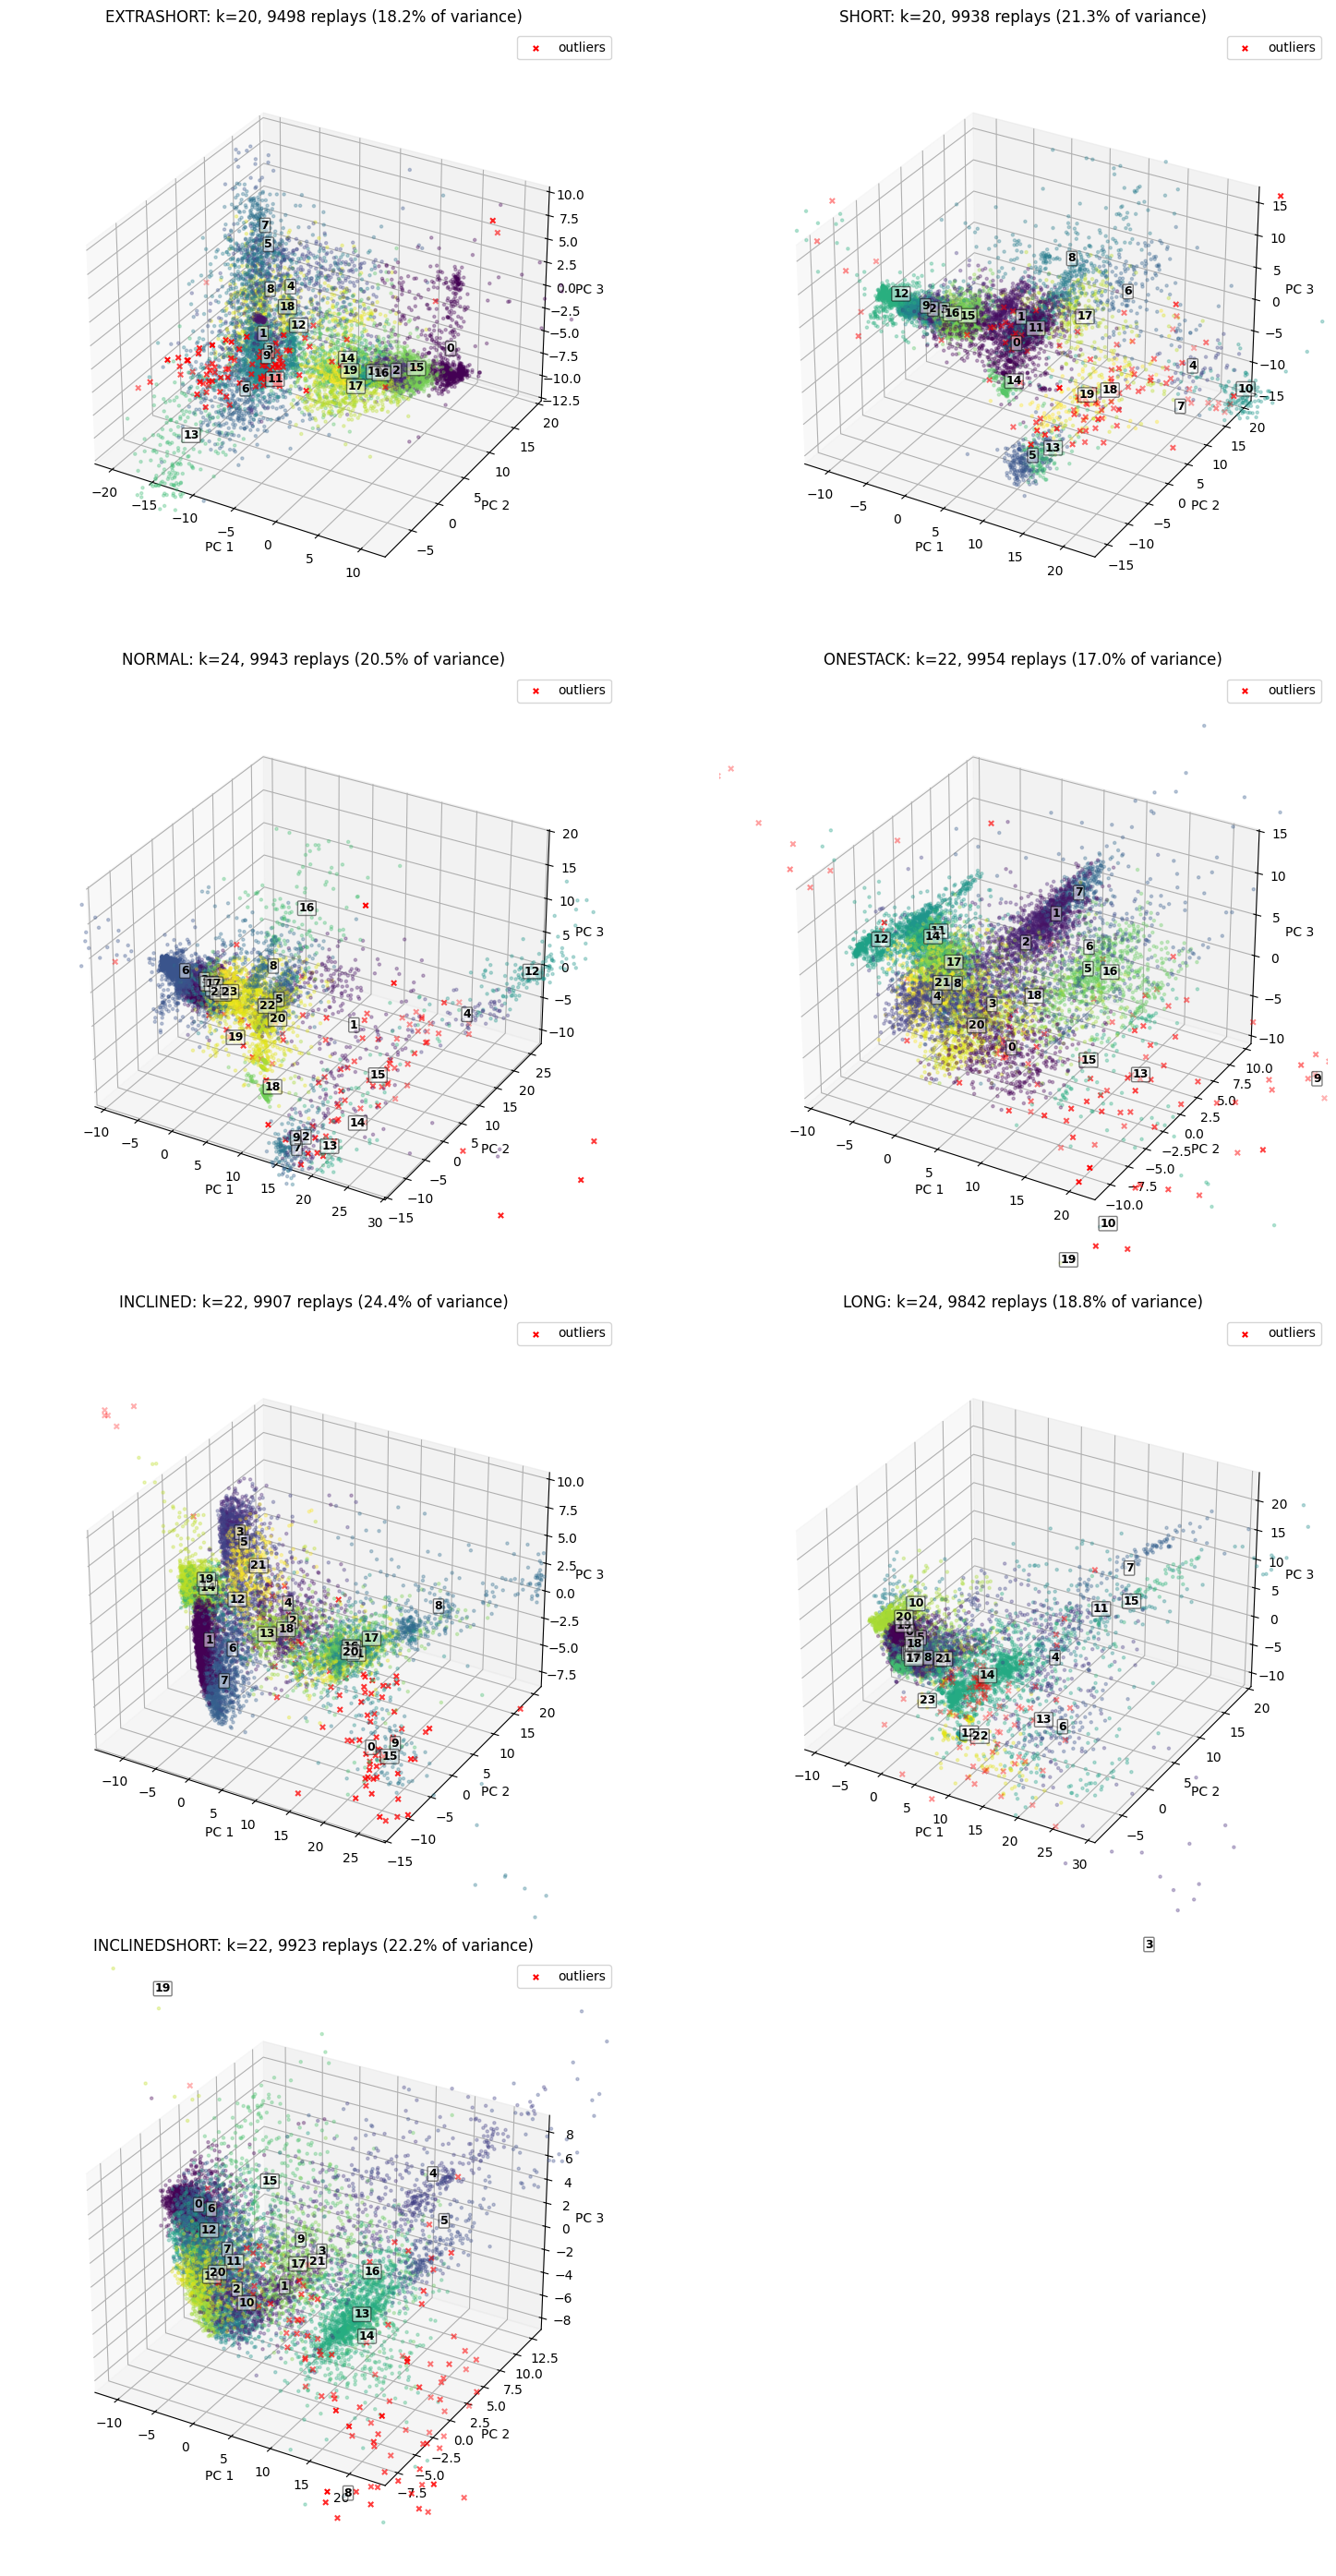

In [102]:
modes_list = list(mcplayhd_results)
graph_rows = math.ceil(len(modes_list) / 2)

fig = plt.figure(figsize=(16, 7 * graph_rows))

for position, mode in enumerate(modes_list, start=1):
    result = mcplayhd_results[mode]
    points = result["reduced"]
    is_outlier = result["is_outlier"]
    pc_share = result["pca"].explained_variance_ratio_[:3].sum()

    ax = fig.add_subplot(graph_rows, 2, position, projection="3d")
    ax.scatter(
        points[~is_outlier, 0], points[~is_outlier, 1], points[~is_outlier, 2],
        c=result["labels"][~is_outlier], cmap="viridis", s=5, alpha=0.3
    )
    ax.scatter(
        points[is_outlier, 0], points[is_outlier, 1], points[is_outlier, 2],
        color="red", marker="x", s=15, label="outliers"
    )

    # cluster number at each centre
    for cluster, center in enumerate(result["kmeans"].cluster_centers_):
        ax.text(
            center[0], center[1], center[2], str(cluster),
            color="black", fontsize=9, fontweight="bold", zorder=100,
            bbox=dict(facecolor="white", alpha=0.5, edgecolor="black", boxstyle="round,pad=0.1")
        )

    # zoom to the middle 99% of the replays, the far outliers would squash the plot
    for axis, set_limits in enumerate([ax.set_xlim, ax.set_ylim, ax.set_zlim]):
        low, high = np.percentile(points[:, axis], [0.5, 99.5])
        set_limits(low, high)

    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.set_zlabel("PC 3")
    ax.set_title(f"{mode}: k={result['kmeans'].n_clusters}, {len(result['ids'])} replays ({pc_share:.1%} of variance)")
    ax.set_box_aspect(None, zoom=0.85)
    ax.legend()

fig.tight_layout()
plt.show()

#### export

In [103]:
cluster_export_rows("mcplayhd_concept", mcplayhd_results).to_csv(MCPLAYHD_EXPORT_PATH, index=False)

## 05 - blocks per click

#### settings

In [36]:
BPC_FEATURES = ["blocks_per_click", "avg_speed"]
BPC_CLUSTER_ELBOW_K_VALUES = range(2, 16)
BPC_CLUSTER_OUTLIER_PERCENTILE = 99


BPC_CLUSTER_COUNTS = {
    "EXTRASHORT": 6,
    "SHORT": 5,
    "NORMAL": 5,
    "LONG": 6,
    "ONESTACK": 8,
    "INCLINED": 7,
    "INCLINEDSHORT": 9,
}

#### preparations

In [37]:
bpc_results = {}
for mode in df_speed_to_block_per_click["fastBuilderMode"].unique():
    df_mode = df_speed_to_block_per_click[df_speed_to_block_per_click["fastBuilderMode"] == mode]
    scaler, scaled = scale(df_mode, BPC_FEATURES)
    bpc_results[mode] = {
        "ids": df_mode["idAnonymous"].to_numpy(),
        "features": df_mode[BPC_FEATURES].to_numpy(),
        "scaler": scaler,
        "scaled": scaled,
    }
    print(f"{mode}: {len(df_mode)} replays")

EXTRASHORT: 9413 replays
SHORT: 9910 replays
NORMAL: 9966 replays
ONESTACK: 9959 replays
INCLINED: 9961 replays
LONG: 9963 replays
INCLINEDSHORT: 9912 replays


#### elbow & silhouette plots

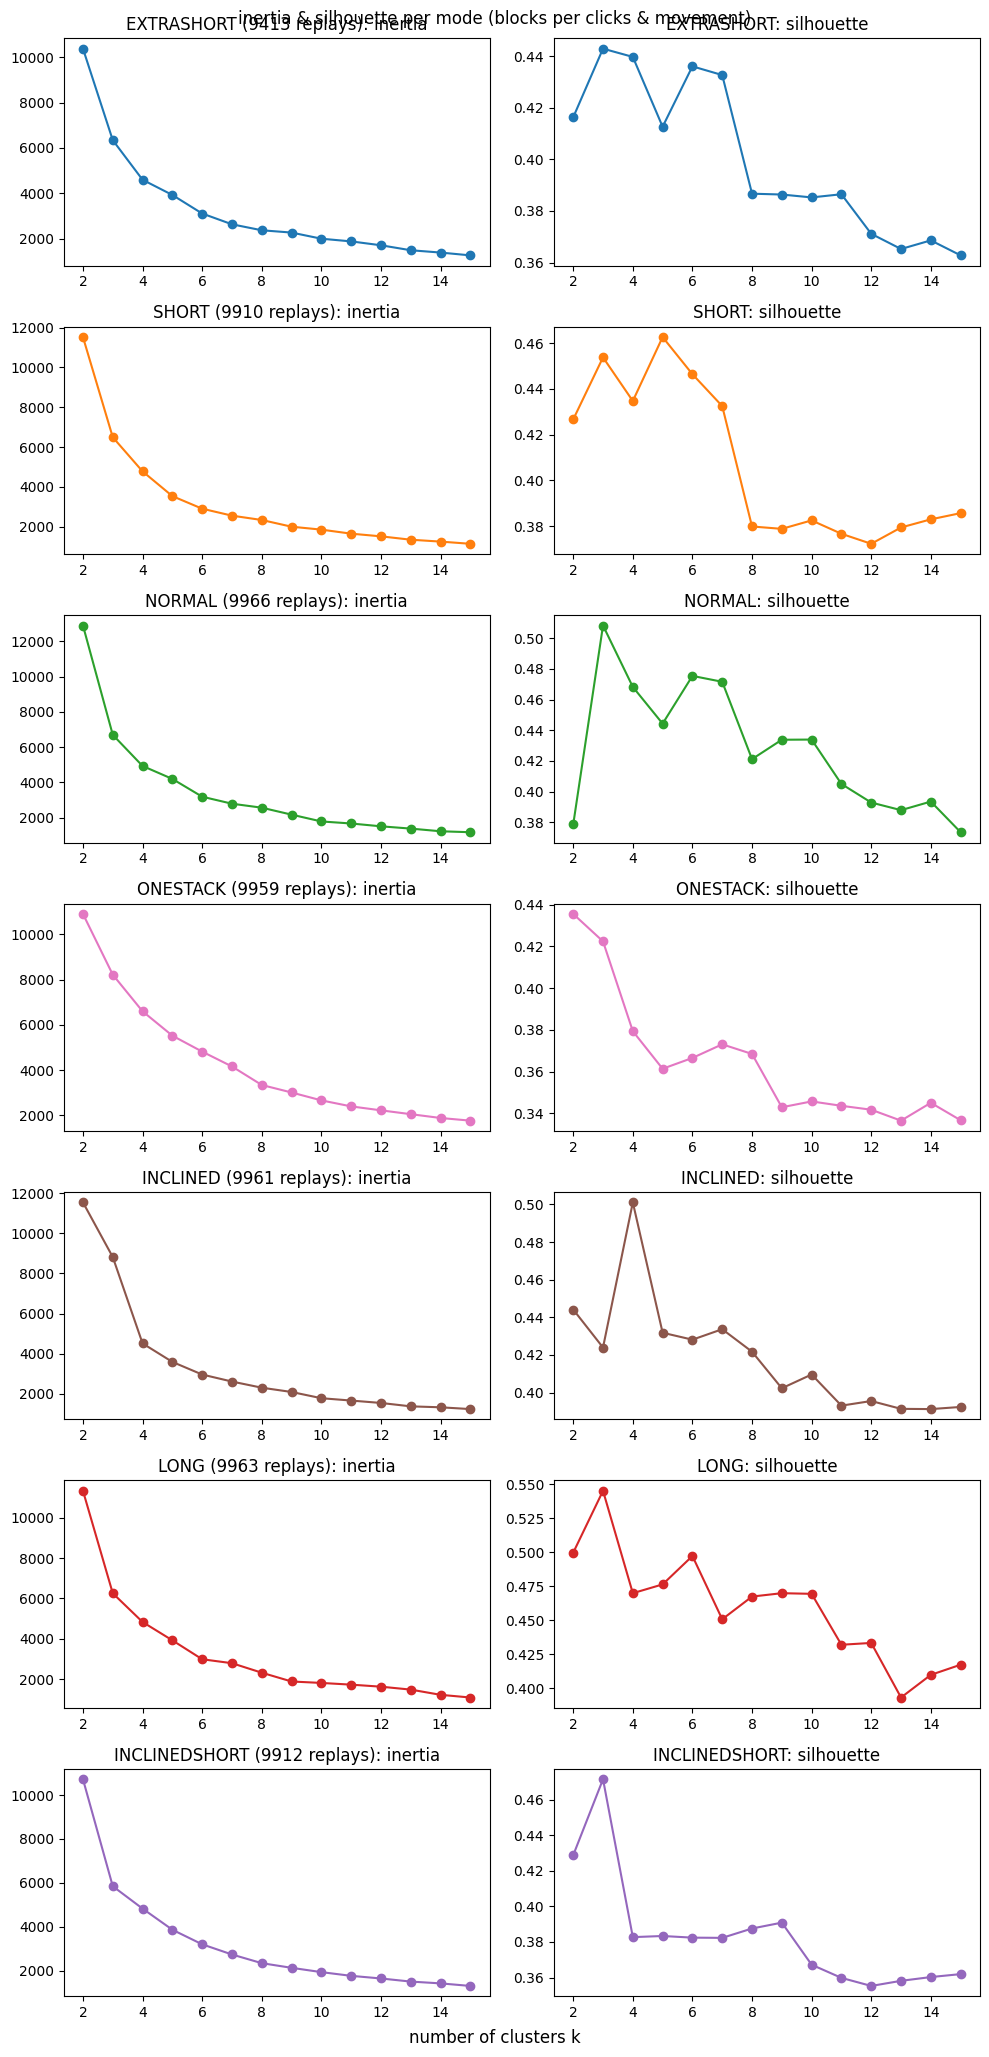

In [38]:
bpc_modes_list = list(bpc_results)
bpc_graph_rows = len(bpc_modes_list)

fig, axes = plt.subplots(bpc_graph_rows, 2, figsize=(10, 3 * bpc_graph_rows))
for row, mode in enumerate(bpc_modes_list):
    inertias, silhouettes = cluster_scores(bpc_results[mode]["scaled"], BPC_CLUSTER_ELBOW_K_VALUES)
    color = MODE_COLORS.get(mode, DEFAULT_MODE_COLOR)
    replay_count = len(bpc_results[mode]["ids"])

    axes[row, 0].plot(BPC_CLUSTER_ELBOW_K_VALUES, inertias, marker="o", color=color)
    axes[row, 0].set_title(f"{mode} ({replay_count} replays): inertia")
    axes[row, 1].plot(BPC_CLUSTER_ELBOW_K_VALUES, silhouettes, marker="o", color=color)
    axes[row, 1].set_title(f"{mode}: silhouette")

fig.supxlabel("number of clusters k")
fig.suptitle("inertia & silhouette per mode (blocks per clicks & movement)")
fig.tight_layout()
plt.show()

| mode          | k-value old | k-value new (10k + r18) |
|---------------|-------------|-------------------------|
| EXTRASHORT    | 6           | 6                       |
| SHORT         | 5           | 5                       |
| NORMAL        | 6           | 5                       |
| LONG          | 7           | 6                       |
| INCLINEDSHORT | 5           | 9                       |
| INCLINED      | 6           | 7                       |
| ONESTACK      | 7           | 8                       |

#### k-means

In [39]:
for mode, result in bpc_results.items():
    kmeans = KMeans(n_clusters=BPC_CLUSTER_COUNTS[mode], random_state=RANDOM_SEED)
    labels = kmeans.fit_predict(result["scaled"])
    nearest_distances = kmeans.transform(result["scaled"]).min(axis=1)
    threshold = np.percentile(nearest_distances, BPC_CLUSTER_OUTLIER_PERCENTILE)

    result["kmeans"] = kmeans
    result["labels"] = labels
    result["nearest_distances"] = nearest_distances
    result["is_outlier"] = nearest_distances > threshold


    print(f"{mode}: k={kmeans.n_clusters}, cluster sizes{np.bincount(labels).tolist()}, outliers {result['is_outlier'].sum()}")

EXTRASHORT: k=6, cluster sizes[1858, 2253, 799, 1477, 1403, 1623], outliers 95
SHORT: k=5, cluster sizes[2496, 2344, 1451, 2876, 743], outliers 100
NORMAL: k=5, cluster sizes[2298, 1906, 960, 3121, 1681], outliers 100
ONESTACK: k=8, cluster sizes[747, 2454, 1857, 979, 553, 34, 2270, 1065], outliers 100
INCLINED: k=7, cluster sizes[2156, 2058, 179, 1809, 1899, 1646, 214], outliers 100
LONG: k=6, cluster sizes[2447, 2649, 468, 1376, 680, 2343], outliers 100
INCLINEDSHORT: k=9, cluster sizes[1264, 1464, 450, 1443, 1655, 136, 1471, 1207, 822], outliers 100


#### plot

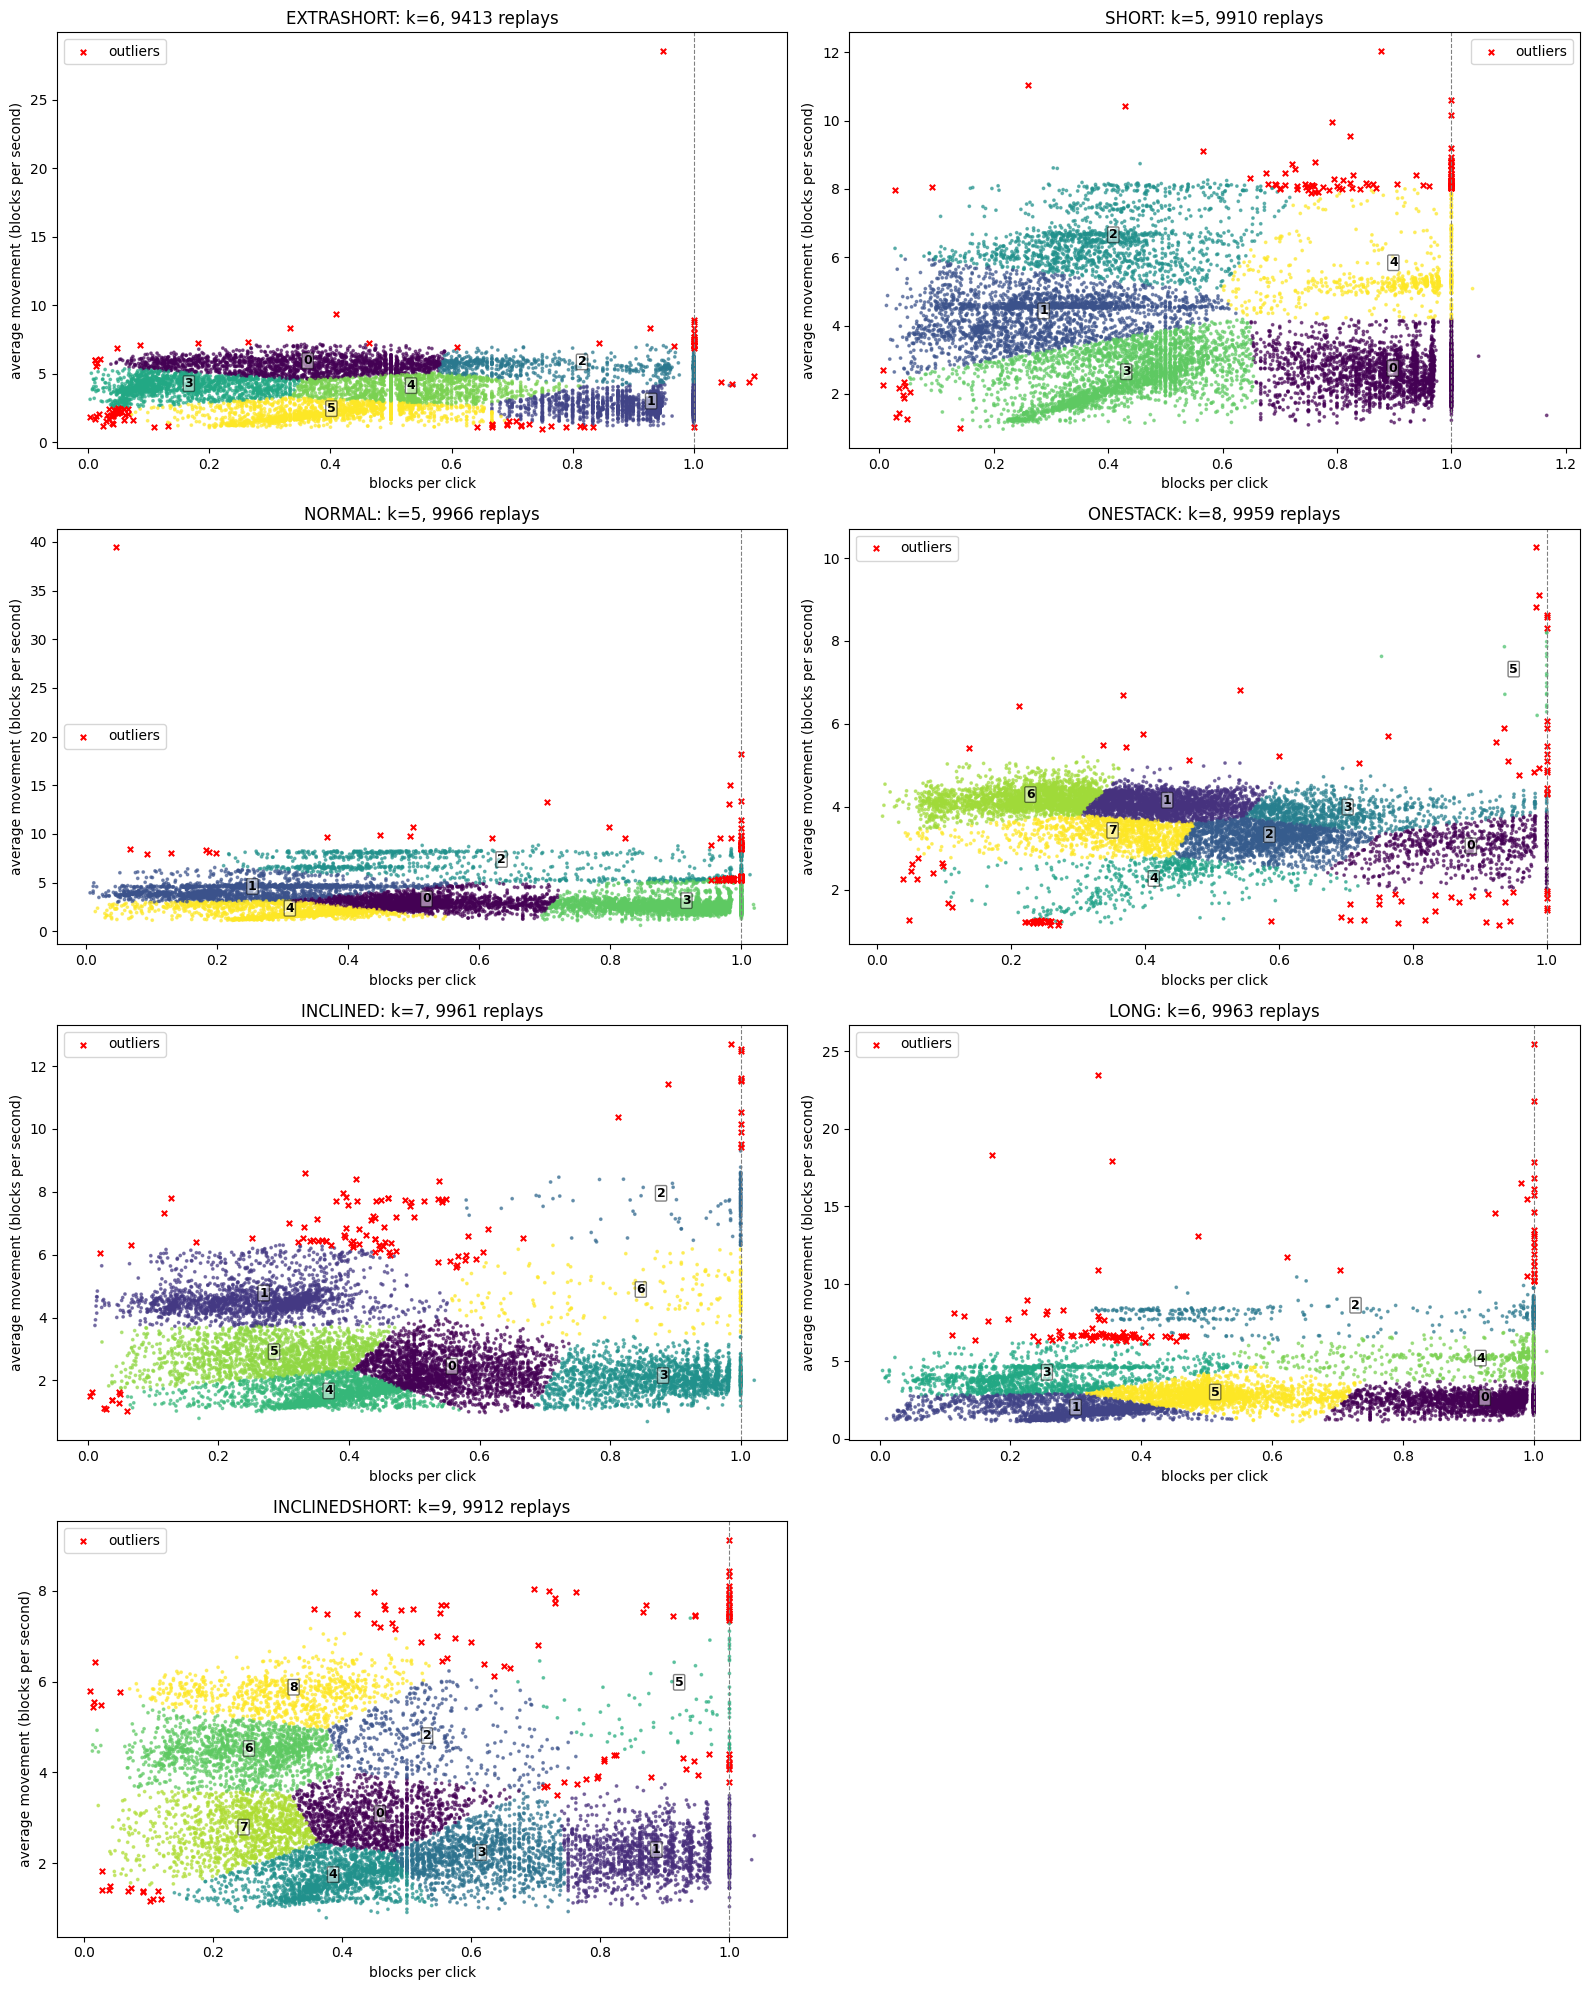

In [40]:
bpc_modes_list = list(bpc_results)
bpc_graph_rows = math.ceil(len(bpc_modes_list) / 2)

fig = plt.figure(figsize=(16, 5 * bpc_graph_rows))

for position, mode in enumerate(bpc_modes_list, start=1):
    result = bpc_results[mode]
    points = result["features"]
    is_outlier = result["is_outlier"]
    # the centres live in scaled units, so convert them back to the real feature units
    centers = result["scaler"].inverse_transform(result["kmeans"].cluster_centers_)

    ax = fig.add_subplot(bpc_graph_rows, 2, position)
    ax.scatter(
        points[~is_outlier, 0], points[~is_outlier, 1],
        c=result["labels"][~is_outlier], cmap="viridis", s=3, alpha=0.6
    )
    ax.scatter(
        points[is_outlier, 0], points[is_outlier, 1],
        color="red", marker="x", s=15, label="outliers"
    )

    # cluster number at each centre
    for cluster, center in enumerate(centers):
        ax.text(
            center[0], center[1], str(cluster),
            color="black", fontsize=9, fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.5, edgecolor="black", boxstyle="round,pad=0.1")
        )

    ax.set_xlabel("blocks per click")
    ax.set_ylabel("average movement (blocks per second)")
    ax.set_title(f"{mode}: k={result['kmeans'].n_clusters}, {len(result['ids'])} replays")
    ax.axvline(1, color="grey", linestyle="--", linewidth=0.8)
    ax.legend()

fig.tight_layout()
plt.show()

## 05b - blocks per click (HDBSCAN)

#### settings

In [47]:
HDBSCAN_TEST_MODE = "SHORT"
HDBSCAN_MIN_CLUSTER_SIZES = [20, 50, 100, 200]
HDBSCAN_MIN_SAMPLES = 10

#### trying min_cluster_size

In [57]:
hdbscan_labels = {}
for size in HDBSCAN_MIN_CLUSTER_SIZES:
    hdbscan = HDBSCAN(min_cluster_size=size, min_samples=HDBSCAN_MIN_SAMPLES, store_centers="medoid", copy=True)
    hdbscan_labels[size] = hdbscan.fit_predict(bpc_results[HDBSCAN_TEST_MODE]["scaled"])

for size, size_labels in hdbscan_labels.items():
    cluster_count = len(np.unique(size_labels))
    if -1 in size_labels:
        cluster_count -= 1

    noise = (size_labels == -1)
    noise_share = noise.sum() / len(size_labels)

    print(f"min_count {size}: {cluster_count} clusters ({noise_share*100:.1f}% noise share)")


min_count 20: 41 clusters (44.2% noise share)
min_count 50: 13 clusters (32.8% noise share)
min_count 100: 8 clusters (30.9% noise share)
min_count 200: 7 clusters (32.2% noise share)


#### plot
(claude generated)

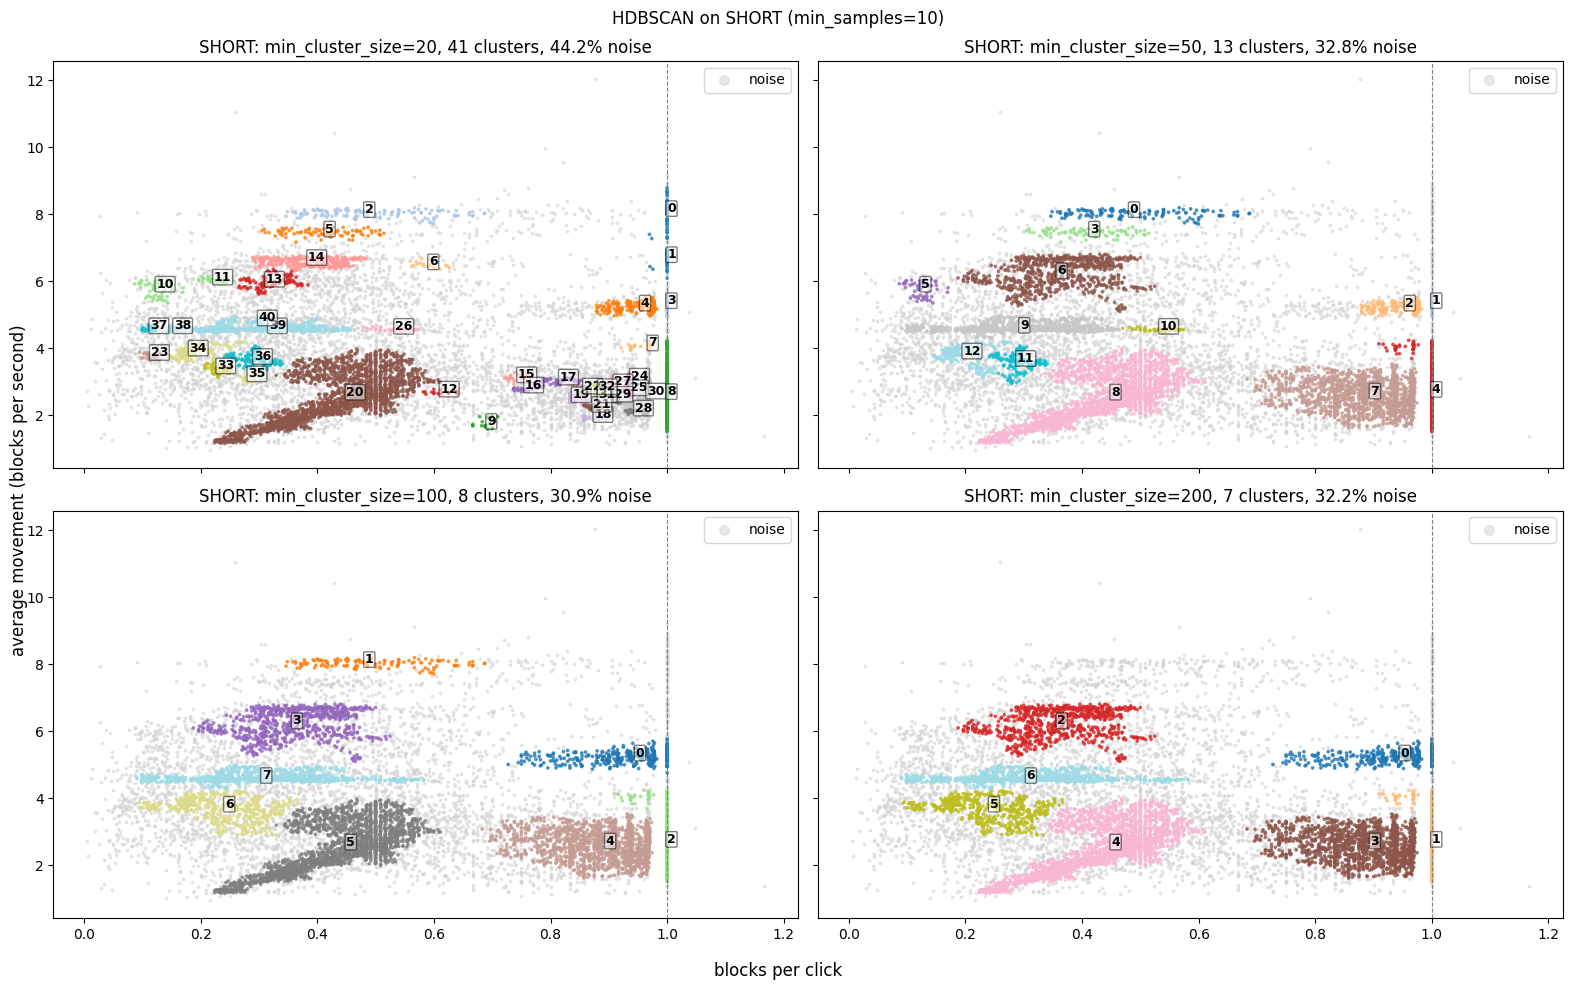

In [58]:
hdbscan_points = bpc_results[HDBSCAN_TEST_MODE]["features"]
hdbscan_graph_rows = math.ceil(len(hdbscan_labels) / 2)

fig, axes = plt.subplots(hdbscan_graph_rows, 2, figsize=(16, 5 * hdbscan_graph_rows), sharex=True, sharey=True, squeeze=False)

for ax, (size, size_labels) in zip(axes.flat, hdbscan_labels.items()):
    noise = size_labels == -1
    cluster_ids = np.unique(size_labels[~noise])

    ax.scatter(
        hdbscan_points[noise, 0], hdbscan_points[noise, 1],
        color="lightgrey", s=3, alpha=0.5, label="noise"
    )
    ax.scatter(
        hdbscan_points[~noise, 0], hdbscan_points[~noise, 1],
        c=size_labels[~noise], cmap="tab20", s=3, alpha=0.7
    )

    # cluster number at the median point of each cluster (HDBSCAN has no centres like k-means)
    for cluster in cluster_ids:
        median = np.median(hdbscan_points[size_labels == cluster], axis=0)
        ax.text(
            median[0], median[1], str(cluster),
            color="black", fontsize=9, fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.5, edgecolor="black", boxstyle="round,pad=0.1")
        )

    ax.set_title(f"{HDBSCAN_TEST_MODE}: min_cluster_size={size}, {len(cluster_ids)} clusters, {noise.mean():.1%} noise")
    ax.axvline(1, color="grey", linestyle="--", linewidth=0.8)
    ax.legend(markerscale=4)

# hide empty subplots if the number of sizes is odd
for ax in axes.flat[len(hdbscan_labels):]:
    ax.set_visible(False)

fig.supxlabel("blocks per click")
fig.supylabel("average movement (blocks per second)")
fig.suptitle(f"HDBSCAN on {HDBSCAN_TEST_MODE} (min_samples={HDBSCAN_MIN_SAMPLES})")
fig.tight_layout()
plt.show()

This approach seems not viable, the clusters seem arbitrary with both k-means and density based clustering. There is a suspicious line around bpc=1, tho, let's try to extract this one at least and verify if it's actually cheaters.

#### extract bpc=1 samples

In [91]:
BPC_LINE_THRESHOLD = 0.95
BPC_LINE_SAMPLE_COUNT = 20

on_line = df_speed_to_block_per_click[df_speed_to_block_per_click["blocks_per_click"] >= BPC_LINE_THRESHOLD]
for mode, df_mode in on_line.groupby("fastBuilderMode"):
    sample = df_mode.sample(n=min(BPC_LINE_SAMPLE_COUNT, len(df_mode)), random_state=RANDOM_SEED)
    sample = sample.sort_values("avg_speed")
    print(mode, sample[["idAnonymous", "blocks_per_click", "avg_speed"]].round(2).to_string(index=False), sep="\n")

EXTRASHORT
 idAnonymous  blocks_per_click  avg_speed
       54584               1.0       1.78
       56655               1.0       1.91
      217390               1.0       1.94
      213007               1.0       1.94
      299071               1.0       2.18
      213965               1.0       2.22
       13996               1.0       2.54
       45475               1.0       2.61
      226999               1.0       2.77
       41425               1.0       2.87
      134561               1.0       2.91
      155072               1.0       2.94
       93940               1.0       2.97
      181250               1.0       3.01
      124862               1.0       3.07
       46706               1.0       3.33
       62335               1.0       3.40
      393645               1.0       3.89
      284019               1.0       5.32
       77744               1.0       6.53
INCLINED
 idAnonymous  blocks_per_click  avg_speed
      238955              1.00       1.74
      163116  

Verifying these samples on the minecraft servers showed that there is a tendency for replays with movement > 6.00 bps seem all suspicious and replays with movement < 4.00 bps all seem not suspicious and just people bridging slowly. The clustering algorithm were not really able to build clusters around that, tho. Therefore, I consider this approach not viable for our clustering use-case.